In [ ]:
# Setup (local environment)
import sys
sys.path.insert(0, '.')
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd
import pickle
import os

# === Caricamento dati V2 (IS-only, parametri ottimali dal sweep) ===

# Carica i risultati completi per ogni combinazione
with open("Data/results_v2.pkl", "rb") as f:
    results = pickle.load(f)

# Carica le statistiche riassuntive delle top 3 strategie v2
top_3 = pd.read_csv("Data/top_3_v2.csv")

# Carica i dati daily OHLC del BTC
from src.data_loader import load_config, load_btc_daily
config = load_config()
df_btc_daily = load_btc_daily(config)
df_btc_daily = df_btc_daily.rename(columns={"date": "Date"})

print(f"Loaded {len(results)} v2 strategies (IS-only)")
print(f"Top 3 combos: {top_3['params'].tolist()}")
print(f"BTC daily: {len(df_btc_daily)} rows")

In [25]:
print(df_btc_daily)

           Date     open     high      low    close
0    2021-05-31  36953.5  37538.5  36850.0  37290.5
1    2021-06-01  37289.0  37914.5  35640.0  36694.5
2    2021-06-02  36696.5  38249.0  35948.5  37591.5
3    2021-06-03  37583.5  39483.0  37184.5  39245.5
4    2021-06-04  39246.0  39294.0  35587.0  36879.5
...         ...      ...      ...      ...      ...
1214 2024-09-26  63151.0  65870.0  62650.5  65180.0
1215 2024-09-27  65184.5  66636.5  64838.0  65799.5
1216 2024-09-28  65800.0  66255.0  65447.0  65887.5
1217 2024-09-29  65888.0  66105.0  65455.0  65637.0
1218 2024-09-30  65627.5  65637.0  63047.0  63740.0

[1219 rows x 5 columns]


In [26]:
print(results.keys())

dict_keys([(0.01, 1, 0.007), (0.01, 1, 0.008), (0.01, 1, 0.009), (0.01, 1, 0.01), (0.01, 1, 0.011), (0.01, 1, 0.012), (0.01, 1, 0.013), (0.01, 1, 0.014), (0.01, 1.5, 0.007), (0.01, 1.5, 0.008), (0.01, 1.5, 0.009), (0.01, 1.5, 0.01), (0.01, 1.5, 0.011), (0.01, 1.5, 0.012), (0.01, 1.5, 0.013), (0.01, 1.5, 0.014), (0.01, 2, 0.007), (0.01, 2, 0.008), (0.01, 2, 0.009), (0.01, 2, 0.01), (0.01, 2, 0.011), (0.01, 2, 0.012), (0.01, 2, 0.013), (0.01, 2, 0.014), (0.01, 2.5, 0.007), (0.01, 2.5, 0.008), (0.01, 2.5, 0.009), (0.01, 2.5, 0.01), (0.01, 2.5, 0.011), (0.01, 2.5, 0.012), (0.01, 2.5, 0.013), (0.01, 2.5, 0.014), (0.02, 1, 0.007), (0.02, 1, 0.008), (0.02, 1, 0.009), (0.02, 1, 0.01), (0.02, 1, 0.011), (0.02, 1, 0.012), (0.02, 1, 0.013), (0.02, 1, 0.014), (0.02, 1.5, 0.007), (0.02, 1.5, 0.008), (0.02, 1.5, 0.009), (0.02, 1.5, 0.01), (0.02, 1.5, 0.011), (0.02, 1.5, 0.012), (0.02, 1.5, 0.013), (0.02, 1.5, 0.014), (0.02, 2, 0.007), (0.02, 2, 0.008), (0.02, 2, 0.009), (0.02, 2, 0.01), (0.02, 2, 0.

In [ ]:
import ast

# Carica top_3_v2.csv e trasforma la colonna "params" in tuple
top_3 = pd.read_csv("Data/top_3_v2.csv")
top_3["params"] = top_3["params"].apply(ast.literal_eval)
print(top_3[["params", "Sharpe", "Num_Trades", "WinRate", "TP_Rate"]])

In [28]:
print(top_3)

               params    Sharpe  WinRate  Num_Trades   TP_Rate      RMSE_TP  \
0  (0.03, 2.0, 0.011)  0.872552  0.52988         251  0.083665  2933.475597   
1  (0.03, 1.5, 0.011)  0.871131  0.52988         251  0.083665  2937.431385   
2  (0.03, 2.5, 0.011)  0.897866  0.52988         251  0.083665  2928.459157   

   Min_Dir_Return  Mean_SL_Return  Max_Drawdown  Sharpe_norm  ...  \
0         0.23487       -9.086755    -21.648227     0.872938  ...   
1         0.23487       -7.208793    -21.648227     0.865805  ...   
2         0.23487        0.000000    -21.648227     1.000000  ...   

   Num_Trades_norm  TP_Rate_norm  RMSE_TP_norm  Min_Dir_Return_norm  \
0              1.0           1.0      0.959442                  1.0   
1              1.0           1.0      0.927459                  1.0   
2              1.0           1.0      1.000000                  1.0   

   Mean_SL_Return_norm  Max_Drawdown_norm      Score   gap  sl_mult  \
0              1.00000                1.0  91.3532

In [ ]:
# Estraggo i df_trades delle top 3 strategie
df_trades_top3 = []

for row in top_3.itertuples(index=False):
    params = row.params
    df = results[params].copy()
    df["strategy_params"] = str(params)
    df_trades_top3.append(df)
    print(f"Strategy {params}: {len(df)} trades, cols={list(df.columns)[:8]}...")

In [ ]:
def max_consecutive_losses(returns):
    count = 0
    max_count = 0
    for r in returns:
        if r < 0:
            count += 1
            max_count = max(max_count, count)
        else:
            count = 0
    return max_count

# Calcola per ciascuna delle top 3 strategie
for i, row in top_3.iterrows():
    params = row["params"]
    df = results[params]
    max_losses = max_consecutive_losses(df["Return_Pct"])
    print(f"Strategia {i+1} ({params}): {max_losses} trade consecutivi in perdita")

In [ ]:
def calcola_initial_margin(position_size_btc):
    """
    Calcola l'Initial Margin richiesto da Deribit per una posizione sul contratto BTC-PERPETUAL.

    Formula:
        IM = 2% + (position_size_btc * 0.005%)

    Parametri:
    - position_size_btc: float → dimensione della posizione espressa in BTC

    Ritorna:
    - initial_margin_percent: float → percentuale di margine richiesta
    """
    im_percent = 0.02 + (position_size_btc * 0.00005)
    return im_percent

In [ ]:
def calcola_commissioni(position_size_usd, maker=False):
    """
    Calcola le commissioni totali (entrata + uscita) per un trade su Deribit BTC-PERPETUAL.

    Parametri:
    - position_size_usd: float → valore nozionale della posizione in USD
    - maker: bool → True se sei maker, False se sei taker

    Ritorna:
    - commissioni_totali_usd: float → fee totali in USD
    """
    fee_per_lato = 0.0 if maker else 0.0005
    commissioni_totali_usd = position_size_usd * fee_per_lato * 2
    return commissioni_totali_usd

In [ ]:
df_trades_top3

[    Entry_Date     Entry_Timestamp      Exit_Timestamp Direction  Spot_Entry  \
 0   2021-06-12 2021-06-12 23:55:00 2021-06-13 23:55:00     SHORT     35548.0   
 1   2021-06-15 2021-06-15 23:55:00 2021-06-16 15:10:00     SHORT     40158.0   
 2   2021-06-20 2021-06-20 23:55:00 2021-06-21 04:10:00     SHORT     35600.5   
 3   2021-06-23 2021-06-23 23:55:00 2021-06-24 23:55:00     SHORT     33655.0   
 4   2021-06-28 2021-06-28 23:55:00 2021-06-29 23:55:00     SHORT     34494.5   
 ..         ...                 ...                 ...       ...         ...   
 246 2024-09-20 2024-09-20 23:55:00 2024-09-21 23:55:00     SHORT     63233.5   
 247 2024-09-21 2024-09-21 23:55:00 2024-09-22 23:55:00      LONG     63385.0   
 248 2024-09-22 2024-09-22 23:55:00 2024-09-23 23:55:00     SHORT     63598.5   
 249 2024-09-28 2024-09-28 23:55:00 2024-09-29 23:55:00      LONG     65887.5   
 250 2024-09-29 2024-09-29 23:55:00 2024-09-30 22:00:00      LONG     65637.0   
 
         Spot_Exit  Return

In [ ]:
import numpy as np

def fixed_fractional_position_size(account_equity, risk_pct, btc_price, sl_pct):
    """
    Fixed Fractional: percentuale dell'equity su ogni trade.
    """
    dollar_risk = account_equity * risk_pct
    position_size_usd = dollar_risk / sl_pct
    contracts = np.floor(position_size_usd / (10 * btc_price))
    min_contracts = 0
    return max(min_contracts, contracts)

def fixed_dollar_risk_position_size(dollar_risk, btc_price, sl_pct):
    """
    Fixed Dollar Risk: rischio fisso in dollari per trade.
    """
    position_size_usd = dollar_risk / sl_pct
    contracts = np.floor(position_size_usd / (10 * btc_price))
    min_contracts = 0
    return max(min_contracts, contracts)

def fixed_contracts_position_size(fixed_contracts):
    """
    Fixed Contracts: numero fisso di contratti.
    """
    return fixed_contracts

def kelly_position_size(win_rate, win_loss_ratio, account_equity, btc_price, sl_pct):
    """
    Kelly Criterion.
    """
    kelly_fraction = win_rate - (1 - win_rate) / win_loss_ratio
    kelly_fraction = max(0, kelly_fraction)  # evitiamo valori negativi
    dollar_risk = account_equity * kelly_fraction
    position_size_usd = dollar_risk / sl_pct
    contracts = np.floor(position_size_usd / (10 * btc_price))
    min_contracts = 0
    return max(min_contracts, contracts)

def volatility_targeting_position_size(vol_target, volatility, btc_price, equity):
    """
    Volatility Targeting corretta: calcola position sizing in base all'equity totale.
    """
    position_size_usd = equity * (vol_target / volatility)
    contracts = np.floor(position_size_usd / (10 * btc_price))
    return max(0, contracts)

def drawdown_based_scaling_position_size(account_equity, max_drawdown_pct, drawdown_pct, base_risk_pct, btc_price, sl_pct):
    """
    Riduce il rischio se il drawdown è elevato.
    """
    if drawdown_pct < max_drawdown_pct:
        adjusted_risk_pct = base_risk_pct
    else:
        adjusted_risk_pct = base_risk_pct * (1 - drawdown_pct / max_drawdown_pct)
    dollar_risk = account_equity * adjusted_risk_pct
    position_size_usd = dollar_risk / sl_pct
    contracts = np.floor(position_size_usd / (10 * btc_price))
    min_contracts = 0
    return max(min_contracts, contracts)

def fixed_ratio_position_size(account_equity, starting_equity, delta, base_contracts=1):
    """
    Fixed Ratio (Ryan Jones): scala il numero di contratti in base all'incremento di equity.
    """
    growth_units = np.floor((account_equity - starting_equity) / delta)
    contracts = base_contracts + growth_units
    return max(1, contracts)

In [ ]:
def fixed_fractional_mm(row, param, equity):
    btc_price = row[param.get("btc_price_col", "Spot_Entry")]
    risk_pct = param["risk_pct"]
    sl_pct = row["SL_Pct"]
    return fixed_fractional_position_size(equity, risk_pct, btc_price, sl_pct)

def fixed_dollar_risk_mm(row, param, equity):
    btc_price = row[param.get("btc_price_col", "Spot_Entry")]
    dollar_risk = param["dollar_risk"]
    sl_pct = row["SL_Pct"]
    return fixed_dollar_risk_position_size(dollar_risk, btc_price, sl_pct)

def fixed_contracts_mm(row, param, equity):
    return fixed_contracts_position_size(param["contracts"])

def kelly_criterion_mm(row, param, equity):
    btc_price = row[param.get("btc_price_col", "Spot_Entry")]
    sl_pct = row["SL_Pct"]
    win_rate = param["win_rate"]
    win_loss_ratio = param["win_loss_ratio"]
    return kelly_position_size(win_rate, win_loss_ratio, equity, btc_price, sl_pct)

def kelly_criterion_mm_walk_forward(df, equity_start, btc_price_col="Spot_Entry", sl_col="SL_Pct", min_obs=10):
    """
    Applica Kelly Criterion in modalità walk-forward:
    - Per ogni trade t, calcola win_rate e win/loss ratio solo sui trade precedenti (t-1, ..., 0)
    - Usa questi valori per determinare la size a t

    Parametri:
    - df: DataFrame dei trade base (copiato già all'interno del loop principale)
    - equity_start: equity iniziale
    - btc_price_col: nome colonna con prezzo BTC
    - sl_col: nome colonna con SL in percentuale
    - min_obs: numero minimo di trade richiesti per stimare Kelly

    Output:
    - df con colonne 'Contracts', 'Position_Size', 'Equity_Curve', ecc.
    """
    equity = equity_start
    equity_curve = []
    contracts_list = []
    size_list = []

    for i in range(len(df)):
        btc_price = df.iloc[i][btc_price_col]
        sl_pct = df.iloc[i][sl_col]
        if i >= min_obs:
            prev_returns = df.iloc[:i]["Return_Pct"] / 100
            wins = prev_returns[prev_returns > 0]
            losses = prev_returns[prev_returns < 0]
            win_rate = len(wins) / len(prev_returns) if len(prev_returns) > 0 else 0
            avg_win = wins.mean() if len(wins) > 0 else 0
            avg_loss = -losses.mean() if len(losses) > 0 else 0
            win_loss_ratio = avg_win / avg_loss if avg_loss > 0 else 1.0
        else:
            # fallback iniziale prudente
            win_rate = 0.5
            win_loss_ratio = 1.0

        # Formula Kelly classica
        kelly_fraction = win_rate - (1 - win_rate) / win_loss_ratio
        kelly_fraction = max(0, kelly_fraction)
        dollar_risk = equity * kelly_fraction
        position_size_usd = dollar_risk / sl_pct
        contracts = np.floor(position_size_usd / (10 * btc_price))
        contracts = max(0, contracts)

        # Salva risultati
        contracts_list.append(contracts)
        size_list.append(contracts * 10 * btc_price)

        # Calcola nuovo equity
        trade_return = df.iloc[i]["Return_Pct"] / 100
        profit = contracts * 10 * btc_price * trade_return
        equity += profit
        equity_curve.append(equity)

    df["Contracts"] = contracts_list
    df["Position_Size"] = size_list
    df["Equity_Curve"] = equity_curve
    df["Return_$"] = df["Equity_Curve"].diff().fillna(0)
    df["Return_Pct_Eq"] = df["Return_$"] / df["Equity_Curve"].shift(1).fillna(equity_start)

    # Calcola anche il drawdown
    peak = df["Equity_Curve"].cummax()
    df["Drawdown_Pct"] = (df["Equity_Curve"] - peak) / peak

    return df

def volatility_targeting_mm(row, param, equity):
    btc_price = row[param.get("btc_price_col", "Spot_Entry")]
    vol_target = param["vol_target"]
    vol_source = param.get("vol_source", "walk")

    # Estrai la volatilità dalla riga, a seconda della colonna scelta
    if vol_source == "walk":
        volatility = row["Walk_Forward_Vol"]
    elif vol_source == "rolling":
        volatility = row["Rolling20_Vol"]
    else:
        raise ValueError("Fonte volatilità non valida. Usa 'walk' o 'rolling'.")

    return volatility_targeting_position_size(vol_target, volatility, btc_price, equity)

def drawdown_scaling_mm(row, param, equity, drawdown_pct):
    btc_price = row[param.get("btc_price_col", "Spot_Entry")]
    sl_pct = row["SL_Pct"]
    base_risk_pct = param["base_risk_pct"]
    max_drawdown_pct = param["max_drawdown_pct"]
    return drawdown_based_scaling_position_size(equity, max_drawdown_pct, drawdown_pct, base_risk_pct, btc_price, sl_pct)

def fixed_ratio_mm(row, param, equity):
    starting_equity = param["starting_equity"]
    delta = param["delta"]
    base_contracts = param.get("base_contracts", 1)
    return fixed_ratio_position_size(equity, starting_equity, delta, base_contracts)

In [ ]:
print(df_trades_top3)

[    Entry_Date     Entry_Timestamp      Exit_Timestamp Direction  Spot_Entry  \
0   2021-06-12 2021-06-12 23:55:00 2021-06-13 23:55:00     SHORT     35548.0   
1   2021-06-15 2021-06-15 23:55:00 2021-06-16 15:10:00     SHORT     40158.0   
2   2021-06-20 2021-06-20 23:55:00 2021-06-21 04:10:00     SHORT     35600.5   
3   2021-06-23 2021-06-23 23:55:00 2021-06-24 23:55:00     SHORT     33655.0   
4   2021-06-28 2021-06-28 23:55:00 2021-06-29 23:55:00     SHORT     34494.5   
..         ...                 ...                 ...       ...         ...   
246 2024-09-20 2024-09-20 23:55:00 2024-09-21 23:55:00     SHORT     63233.5   
247 2024-09-21 2024-09-21 23:55:00 2024-09-22 23:55:00      LONG     63385.0   
248 2024-09-22 2024-09-22 23:55:00 2024-09-23 23:55:00     SHORT     63598.5   
249 2024-09-28 2024-09-28 23:55:00 2024-09-29 23:55:00      LONG     65887.5   
250 2024-09-29 2024-09-29 23:55:00 2024-09-30 22:00:00      LONG     65637.0   

        Spot_Exit  Return_Pct Exit_Typ

In [ ]:
def apply_money_management_debug(df_trades_base, mm_func, mm_params, equity_start, equity_col='Equity', debug=False, N_debug=3):
    equity = equity_start
    drawdown_pct = 0
    max_equity = equity_start
    results = []

    for i, row in df_trades_base.iterrows():
        if results:
            equity = results[-1][equity_col]
            max_equity = max(max_equity, equity)
            drawdown_pct = (max_equity - equity) / max_equity

        try:
            if debug and len(results) < N_debug:
                print(f"\n--- Trade #{len(results)+1} ---")
                print(f"Equity: {equity}")
                print(f"Row: {row.to_dict()}")
                print(f"Drawdown %: {drawdown_pct:.4f}")
                print(f"MM Params: {mm_params}")

            if mm_func.__name__ == 'drawdown_scaling_mm':
                contracts = mm_func(row, mm_params, equity, drawdown_pct)
            else:
                contracts = mm_func(row, mm_params, equity)

            contracts = float(contracts)
            contracts = max(0, contracts)

            ret_pct = row['Return_Pct']
            trade_return = contracts * 10 * row['Spot_Entry'] * ret_pct / 100
            new_equity = equity + trade_return

            results.append({
                **row,
                'Contracts': contracts,
                'Trade_Return': trade_return,
                equity_col: new_equity
            })

            if debug and len(results) <= N_debug:
                print(f"→ Contracts: {contracts}")
                print(f"→ Trade Return: {trade_return}")
                print(f"→ New Equity: {new_equity}")

        except Exception as e:
            print(f"\n❌ Errore nel trade #{i}: {e}")
            print(f"Riga problematica: {row.to_dict()}")
            raise

    return pd.DataFrame(results)

In [ ]:
df_trades_top3

[    Entry_Date     Entry_Timestamp      Exit_Timestamp Direction  Spot_Entry  \
 0   2021-06-12 2021-06-12 23:55:00 2021-06-13 23:55:00     SHORT     35548.0   
 1   2021-06-15 2021-06-15 23:55:00 2021-06-16 15:10:00     SHORT     40158.0   
 2   2021-06-20 2021-06-20 23:55:00 2021-06-21 04:10:00     SHORT     35600.5   
 3   2021-06-23 2021-06-23 23:55:00 2021-06-24 23:55:00     SHORT     33655.0   
 4   2021-06-28 2021-06-28 23:55:00 2021-06-29 23:55:00     SHORT     34494.5   
 ..         ...                 ...                 ...       ...         ...   
 246 2024-09-20 2024-09-20 23:55:00 2024-09-21 23:55:00     SHORT     63233.5   
 247 2024-09-21 2024-09-21 23:55:00 2024-09-22 23:55:00      LONG     63385.0   
 248 2024-09-22 2024-09-22 23:55:00 2024-09-23 23:55:00     SHORT     63598.5   
 249 2024-09-28 2024-09-28 23:55:00 2024-09-29 23:55:00      LONG     65887.5   
 250 2024-09-29 2024-09-29 23:55:00 2024-09-30 22:00:00      LONG     65637.0   
 
         Spot_Exit  Return

In [ ]:
def apply_money_management(df_base, mm_strategy_fn, mm_param, initial_equity):
    df = df_base.copy()

    equity = initial_equity
    equity_curve = [equity]
    peak_equity = equity
    drawdown_list = []

    contracts_list = []
    equity_after_trade_list = []

    for idx, row in df.iterrows():
        # 🔹 Calcola drawdown corrente
        drawdown_pct = (equity - peak_equity) / peak_equity

        # 🔹 Calcolo dei contratti
        if mm_strategy_fn.__name__ == "drawdown_scaling_mm":
            contracts = mm_strategy_fn(row, mm_param, equity, drawdown_pct)
        else:
            contracts = mm_strategy_fn(row, mm_param, equity)

        contracts_list.append(contracts)

        # 🔹 Calcolo guadagno/perdita in USD
        spot_entry = row["Spot_Entry"]
        return_pct = row["Return_Pct"]
        trade_return = contracts * 10 * spot_entry * (return_pct / 100)  # PnL in USD
        equity += trade_return
        equity_after_trade_list.append(equity)

        # 🔹 Aggiorna equity curve
        equity_curve.append(equity)

        # 🔹 Aggiorna drawdown
        peak_equity = max(peak_equity, equity)
        drawdown_list.append(drawdown_pct)

    df["Equity"] = equity_after_trade_list
    df["Contracts"] = contracts_list
    df["Equity_Curve"] = equity_curve[1:]
    df["Drawdown_Pct"] = drawdown_list

    # 🔁 Ricalcolo dei return effettivi
    df["Return_Pct"] = df["Equity_Curve"].pct_change().fillna(0) * 100

    return df

In [ ]:
import numpy as np

def extract_mm_stats(df_trades_base):
    """
    Estrae le metriche necessarie per strategie MM dinamiche:
    - Kelly
    - Volatility Targeting
    - Drawdown-Based Scaling

    Parametri:
    - df_trades_base: DataFrame contenente i trade della strategia base (colonna 'Return_Pct')

    Ritorna:
    - dict con:
        - win_rate
        - win_loss_ratio
        - volatility (std dei rendimenti giornalieri annualizzata)
        - max_drawdown_pct (massimo drawdown in percentuale sulla equity curve)
    """
    returns = df_trades_base["Return_Pct"].values / 100  # normalizziamo in decimali

    # === Kelly ===
    wins = returns[returns > 0]
    losses = returns[returns < 0]
    win_rate = len(wins) / len(returns) if len(returns) > 0 else 0
    avg_win = np.mean(wins) if len(wins) > 0 else 0
    avg_loss = -np.mean(losses) if len(losses) > 0 else 0
    win_loss_ratio = avg_win / avg_loss if avg_loss > 0 else 0

    # === Volatility Targeting === (std giornaliera annualizzata)
    volatility = np.std(returns) * np.sqrt(252) if len(returns) > 1 else 0

    # === Drawdown ===
    equity = (1 + returns).cumprod()
    peak = np.maximum.accumulate(equity)
    drawdowns = (equity - peak) / peak
    max_drawdown_pct = drawdowns.min()

    return {
        "win_rate": win_rate,
        "win_loss_ratio": win_loss_ratio,
        "volatility": volatility,
        "max_drawdown_pct": abs(max_drawdown_pct)
    }

In [ ]:
def calcola_metriche(df_trades, strategy_id, mm_strategy, mm_param):
    # Se mancano, aggiungi Exit_Date ed Equity_Curve
    if "Exit_Date" not in df_trades.columns:
        df_trades["Exit_Date"] = pd.to_datetime(df_trades["Exit_Timestamp"]).dt.floor("D")
    if "Equity_Curve" not in df_trades.columns:
        df_trades["Equity_Curve"] = (1 + df_trades["Return_Pct"]).cumprod()

    returns = df_trades["Return_Pct"]

    # Calcolo durata in giorni
    start_date = pd.to_datetime(df_trades["Entry_Date"]).min()
    end_date = pd.to_datetime(df_trades["Exit_Date"]).max()
    n_days = (end_date - start_date).days
    n_trades = len(df_trades)
    trades_per_year = (n_trades / n_days) * 365 if n_days > 0 else 0

    # Sharpe annualizzato corretto
    sharpe = (returns.mean() / returns.std()) * np.sqrt(trades_per_year) if returns.std() != 0 else 0

    # Equity curve e drawdown
    equity = df_trades["Equity_Curve"]
    peak = equity.cummax()
    drawdown_pct = ((equity - peak) / peak).min()
    cumulative_return = (equity.iloc[-1] / equity.iloc[0]) - 1
    win_rate = (returns > 0).sum() / len(returns)
    max_losses = max_consecutive_losses(returns)

    # Final Equity
    final_equity = equity.iloc[-1]

    # CAGR
    n_years = n_days / 365.25
    cagr = (final_equity / equity.iloc[0])**(1 / n_years) - 1 if n_years > 0 and final_equity > 0 else np.nan

    return {
        "Strategy_ID": strategy_id,
        "MM_Strategy": mm_strategy,
        "MM_Param": mm_param,
        "Sharpe_Ratio": sharpe,
        "Max_Drawdown_Pct": abs(drawdown_pct),
        "Cumulative_Return": cumulative_return,
        "Win_Rate": win_rate,
        "Max_Consecutive_Losses": max_losses,
        "Trade_Returns": returns.tolist(),
        "Final_Equity": final_equity,
        "CAGR": cagr
    }

In [ ]:
from joblib import Parallel, delayed

def process_single_param(strategy_id, mm_name, mm_func, param, df_base, equity_start, btc_price_source):
    if mm_name == "Kelly Criterion":
        df = kelly_criterion_mm_walk_forward(df_base.copy(), equity_start,
                                             btc_price_col=btc_price_source)
    else:
        df = apply_money_management(df_base.copy(), mm_func, param, initial_equity=equity_start)

    df["Strategy_ID"] = strategy_id
    df["MM_Strategy"] = mm_name
    df["MM_Param"] = [param] * len(df)

    metrics = calcola_metriche(df, strategy_id, mm_name, param)
    return metrics, df

def run_all_money_management_strategies(df_trades_top3, equity_start, btc_price_source="Spot_Entry"):
    all_results = []
    all_detailed = []

    mm_functions = {
        "Fixed Fractional": fixed_fractional_mm,
        "Fixed Dollar Risk": fixed_dollar_risk_mm,
        "Fixed Contracts": fixed_contracts_mm,
        "Kelly Criterion": lambda row, param, equity: np.nan,  # gestita separatamente
        "Volatility Targeting": volatility_targeting_mm,
        "Drawdown Scaling": drawdown_scaling_mm,
        "Fixed Ratio": fixed_ratio_mm
    }

    for strategy_id, df_base in df_trades_top3.items():
        df_base = df_base.copy()
        df_base["Equity_Curve_Temp"] = (1 + df_base["Return_Pct"]).cumprod()
        df_base["Peak"] = df_base["Equity_Curve_Temp"].cummax()
        df_base["Drawdown"] = (df_base["Equity_Curve_Temp"] - df_base["Peak"]) / df_base["Peak"]

        return_pct = df_base["Return_Pct"].astype(float)
        walk_forward_volatility = return_pct.expanding(min_periods=2).std().shift(1)
        walk_forward_volatility.fillna(return_pct.std(), inplace=True)
        df_base["Walk_Forward_Vol"] = walk_forward_volatility

        rolling_window_volatility = return_pct.rolling(window=20, min_periods=2).std().shift(1)
        rolling_window_volatility.fillna(return_pct.std(), inplace=True)
        df_base["Rolling20_Vol"] = rolling_window_volatility

        for mm_name, mm_func in mm_functions.items():
            if mm_name == "Fixed Fractional":
                param_values = [{"risk_pct": p} for p in np.arange(0.005, 3.51, 0.005)]
            elif mm_name == "Fixed Dollar Risk":
                param_values = [{"dollar_risk": d} for d in np.arange(50_000, 20_000_001, 50_000)]
            elif mm_name == "Fixed Contracts":
                param_values = [{"contracts": c} for c in np.arange(1, 1001, 5)]
            elif mm_name == "Kelly Criterion":
                param_values = [{"walk_forward": True}]
            elif mm_name == "Volatility Targeting":
                param_values = [
                    {
                        "vol_target": vol_target,
                        "vol_source": vol_source,
                        "btc_price_col": btc_price_source
                    }
                    for vol_target in np.arange(1.0, 200.1, 0.5)
                    for vol_source in ["walk", "rolling"]
                ]
            elif mm_name == "Drawdown Scaling":
                drawdown_range = np.arange(0.05, 1.01, 0.05)
                base_risk_range = np.arange(0.005, 2.01, 0.005)
                param_values = [
                    {
                        "drawdown_pct": dd,
                        "max_drawdown_pct": dd,
                        "base_risk_pct": risk,
                        "btc_price_col": btc_price_source
                    }
                    for dd in drawdown_range
                    for risk in base_risk_range
                ]
            elif mm_name == "Fixed Ratio":
                param_values = [
                    {"starting_equity": equity_start, "delta": delta, "base_contracts": base}
                    for delta in [500, 1_000, 5_000, 10_000, 25_000, 50_000, 100_000, 200_000, 500_000,
                                  1_000_000, 1_500_000, 2_000_000, 5_000_000, 10_000_000]
                    for base in np.arange(1, 1001, 5)
                ]

            # ✅ Parallelizzazione del ciclo interno
            results = Parallel(n_jobs=-1, backend="loky", verbose=0)(
                delayed(process_single_param)(
                    strategy_id, mm_name, mm_func, param, df_base, equity_start, btc_price_source
                )
                for param in param_values
            )

            for metrics, df in results:
                all_results.append(metrics)
                all_detailed.append(df)

    df_summary = pd.DataFrame(all_results)
    return df_summary, all_detailed

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

def evaluate_best_mm_strategies(df_summary):
    """
    Valuta tutte le combinazioni MM e restituisce un DataFrame ordinato per robustezza.

    Punteggio finale costruito con:
    - Sharpe Ratio: da massimizzare
    - Max Drawdown: da minimizzare
    - Cumulative Return: da massimizzare
    - Win Rate: da massimizzare
    - Max Consecutive Losses: da minimizzare

    Parametri:
    - df_summary: DataFrame con tutte le metriche delle strategie

    Ritorna:
    - DataFrame ordinato per 'Score'
    """
    if 'Max_Consecutive_Losses' not in df_summary.columns:
        df_summary["Max_Consecutive_Losses"] = df_summary["Trade_Returns"].apply(max_consecutive_losses)

    cols_to_normalize = [
    "Sharpe_Ratio",
    "Cumulative_Return",
    "Win_Rate",
    "Max_Drawdown_Pct",
    "Max_Consecutive_Losses",
    "CAGR"                       # ✅ nuovo campo
    ]

    df_norm = df_summary.copy()
    scaler = MinMaxScaler()

    for col in ["Max_Drawdown_Pct", "Max_Consecutive_Losses"]:
        inv_col = col + "_inv"
        df_norm[inv_col] = df_summary[col].max() - df_summary[col]
        cols_to_normalize[cols_to_normalize.index(col)] = inv_col

    df_norm_scaled = pd.DataFrame(scaler.fit_transform(df_norm[cols_to_normalize]), columns=cols_to_normalize)

    weights = {
        "Sharpe_Ratio": 0.25,
        "Cumulative_Return": 0.20,
        "CAGR": 0.15,
        "Win_Rate": 0.15,
        "Max_Drawdown_Pct_inv": 0.15,
        "Max_Consecutive_Losses_inv": 0.10,
    }

    df_norm["Score"] = sum(df_norm_scaled[col] * weights[col] for col in cols_to_normalize)
    df_sorted = df_norm.sort_values(by="Score", ascending=False).reset_index(drop=True)

    return df_sorted

In [ ]:
window_size = 20  # puoi cambiarlo se vuoi

for i, df in enumerate(df_trades_top3):
    # Calcola la deviazione standard cumulativa fino al giorno precedente
    walk_forward_vol = (
        df["Return_Pct"].astype(float)
        .expanding(min_periods=2)
        .std()
        .shift(1)
    )

    rolling_window_vol = (
        df["Return_Pct"].astype(float)
        .rolling(window=window_size, min_periods=2)
        .std()
        .shift(1)  # opzionale: esclude il trade corrente
    )

    # Stampa l'intestazione e i primi valori
    print(f"--- Strategia {i} WALK-FORWARD ---")
    print(walk_forward_vol.head(10))
    print()
    print(walk_forward_vol.describe())
    print()

    # Stampa l'intestazione e i primi valori
    print(f"--- Strategia {i} ROLLING WINDOW ---")
    print(rolling_window_vol.head(10))
    print()
    print(rolling_window_vol.describe())
    print()

--- Strategia 0 WALK-FORWARD ---
0         NaN
1         NaN
2    9.586181
3    7.982947
4    6.622580
5    5.886299
6    5.391497
7    4.939812
8    4.963358
9    4.875476
Name: Return_Pct, dtype: float64

count    249.000000
mean       2.828986
std        0.791346
min        2.276528
25%        2.478817
50%        2.540763
75%        3.049953
max        9.586181
Name: Return_Pct, dtype: float64

--- Strategia 0 ROLLING WINDOW ---
0         NaN
1         NaN
2    9.586181
3    7.982947
4    6.622580
5    5.886299
6    5.391497
7    4.939812
8    4.963358
9    4.875476
Name: Return_Pct, dtype: float64

count    249.000000
mean       2.433834
std        1.174807
min        0.665481
25%        1.572747
50%        2.318393
75%        3.202546
max        9.586181
Name: Return_Pct, dtype: float64

--- Strategia 1 WALK-FORWARD ---
0         NaN
1         NaN
2    9.586181
3    7.982947
4    6.622580
5    5.886299
6    5.391497
7    4.939812
8    4.963358
9    4.875476
Name: Return_Pct, dtype

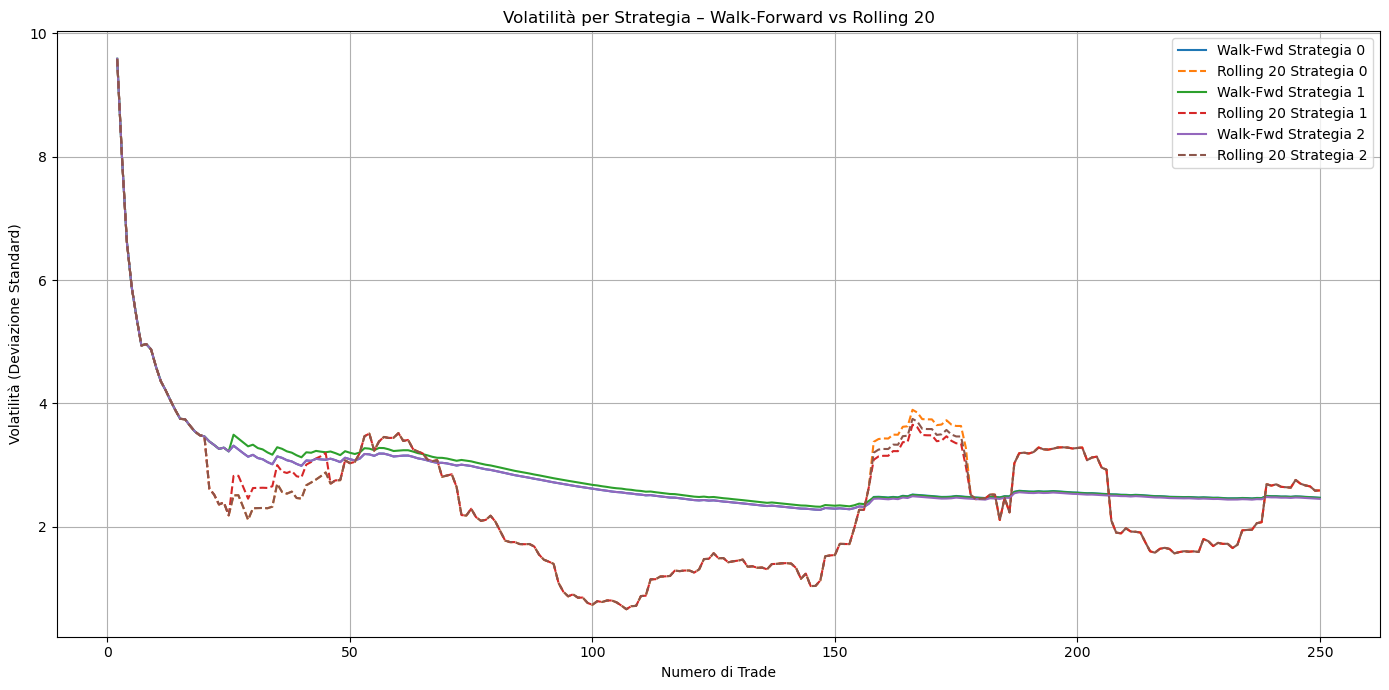

In [ ]:
import matplotlib.pyplot as plt

window_size = 20  # puoi cambiarlo se vuoi

plt.figure(figsize=(14, 7))

for i, df in enumerate(df_trades_top3):
    # Calcolo walk-forward volatility (expanding)
    walk_forward_vol = (
        df["Return_Pct"].astype(float)
        .expanding(min_periods=2)
        .std()
        .shift(1)
    )

    # Calcolo rolling window volatility
    rolling_window_vol = (
        df["Return_Pct"].astype(float)
        .rolling(window=window_size, min_periods=2)
        .std()
        .shift(1)
    )

    # Plot
    plt.plot(walk_forward_vol.values, label=f"Walk-Fwd Strategia {i}", linestyle='-')
    plt.plot(rolling_window_vol.values, label=f"Rolling {window_size} Strategia {i}", linestyle='--')

plt.title(f"Volatilità per Strategia – Walk-Forward vs Rolling {window_size}")
plt.xlabel("Numero di Trade")
plt.ylabel("Volatilità (Deviazione Standard)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Costruisci dizionario da lista
df_trades_top3_dict = {
    df['strategy_params'].iloc[0]: df
    for df in df_trades_top3
}

In [ ]:
df_summary, detailed_trades = run_all_money_management_strategies(df_trades_top3_dict, equity_start=10_000_000)

/var/folders/qw/c_tdl_b155gd0ww9htf_yj_c0000gp/T/ipykernel_61391/1477672552.py:33: RuntimeWarning: invalid value encountered in scalar power
/var/folders/qw/c_tdl_b155gd0ww9htf_yj_c0000gp/T/ipykernel_61391/1477672552.py:33: RuntimeWarning: invalid value encountered in scalar power
/var/folders/qw/c_tdl_b155gd0ww9htf_yj_c0000gp/T/ipykernel_61391/1477672552.py:33: RuntimeWarning: invalid value encountered in scalar power
/var/folders/qw/c_tdl_b155gd0ww9htf_yj_c0000gp/T/ipykernel_61391/1477672552.py:33: RuntimeWarning: invalid value encountered in scalar power
/var/folders/qw/c_tdl_b155gd0ww9htf_yj_c0000gp/T/ipykernel_61391/1477672552.py:33: RuntimeWarning: invalid value encountered in scalar power
/var/folders/qw/c_tdl_b155gd0ww9htf_yj_c0000gp/T/ipykernel_61391/1477672552.py:33: RuntimeWarning: invalid value encountered in scalar power
/var/folders/qw/c_tdl_b155gd0ww9htf_yj_c0000gp/T/ipykernel_61391/1477672552.py:33: RuntimeWarning: invalid value encountered in scalar power
/var/folders/

KeyboardInterrupt: 

In [ ]:
df_summary

NameError: name 'df_summary' is not defined

In [ ]:
df_summary.sort_values(by="Cumulative_Return", ascending=False).head(1)

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR
26939,"(0.03, 2.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 19950000},0.557837,0.681826,5255.294895,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.203166e+08,12.392068


In [ ]:
df_summary.sort_values(by="CAGR", ascending=False).head(1)

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR
26939,"(0.03, 2.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 19950000},0.557837,0.681826,5255.294895,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.203166e+08,12.392068


In [ ]:
df_summary["Trade_Returns"].apply(len).value_counts().sort_index()

Trade_Returns
251    38760
Name: count, dtype: int64

In [ ]:
df_summary["Trade_Returns"]

0        [0.0, 0.15032807610058097, 0.15172865134631675...
1        [0.0, 0.45256299430738167, 0.4554051018399452,...
2        [0.0, 0.6055371370072171, 0.608413404095054, -...
3        [0.0, 0.9115078419231093, 0.9130605697165617, ...
4        [0.0, 1.2196435144046225, 1.2180019448843282, ...
                               ...                        
38755    [0.0, -60.761954531216354, -156.8544830323848,...
38756    [0.0, -60.63471579886919, -156.0184495306186, ...
38757    [0.0, -60.509296468142956, -155.19964295539293...
38758    [0.0, -60.3856577923026, -154.39753628119837, ...
38759    [0.0, -60.26376211708001, -153.6116237633196, ...
Name: Trade_Returns, Length: 38760, dtype: object

In [ ]:
min_losses = df_summary["Max_Consecutive_Losses"].min()
max_losses = df_summary["Max_Consecutive_Losses"].max()

print(f"Minimo Max_Consecutive_Losses: {min_losses}")
print(f"Massimo Max_Consecutive_Losses: {max_losses}")

Minimo Max_Consecutive_Losses: 0
Massimo Max_Consecutive_Losses: 16


In [ ]:
df_ranked = evaluate_best_mm_strategies(df_summary)
df_ranked[[
    "Strategy_ID", "MM_Strategy", "MM_Param",
    "Sharpe_Ratio", "Max_Drawdown_Pct",
    "Win_Rate", "Cumulative_Return",
    "Max_Consecutive_Losses", "Score",
    "CAGR", "Final_Equity"
]].head(10)

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Win_Rate,Cumulative_Return,Max_Consecutive_Losses,Score,CAGR,Final_Equity
0,"(0.03, 2.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 19950000},0.557837,0.681826,0.52988,5255.294895,7,0.877888,12.392068,1.203166e+08
1,"(0.03, 2.0, 0.011)",Fixed Dollar Risk,{'dollar_risk': 15950000},0.557797,0.680312,0.52988,5151.578208,7,0.875619,12.311480,1.179425e+08
2,"(0.03, 1.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 11950000},0.558413,0.704790,0.52988,5148.410871,7,0.875603,12.309002,1.178700e+08
3,"(0.03, 2.5, 0.011)",Fixed Contracts,{'contracts': 286},0.573481,0.800509,0.52988,2648.301256,7,0.816857,9.882582,6.064251e+07
4,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.573709,0.803791,0.52988,2642.508155,7,0.816720,9.875369,6.050990e+07
5,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 5000000...",0.574087,0.807538,0.52988,2640.269883,7,0.816692,9.872580,6.045867e+07
6,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 2000000...",0.575040,0.818337,0.52988,2628.834785,7,0.816465,9.858302,6.019692e+07
7,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1500000...",0.575870,0.826613,0.52988,2620.026225,7,0.816298,9.847274,5.999529e+07
8,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.577076,0.839729,0.52988,2594.372209,7,0.815703,9.815009,5.940807e+07
9,"(0.03, 2.0, 0.011)",Fixed Contracts,{'contracts': 286},0.573470,0.800509,0.52988,2571.655009,7,0.814767,9.786251,5.888807e+07


In [ ]:
df_ranked.sort_values("Cumulative_Return", ascending=False).iloc[0]

Strategy_ID                                                  (0.03, 2.5, 0.011)
MM_Strategy                                                   Fixed Dollar Risk
MM_Param                                              {'dollar_risk': 19950000}
Sharpe_Ratio                                                           0.557837
Max_Drawdown_Pct                                                       0.681826
Cumulative_Return                                                   5255.294895
Win_Rate                                                                0.52988
Max_Consecutive_Losses                                                        7
Trade_Returns                 [0.0, 35069.98367745797, 98.71967190606033, -2...
Final_Equity                                                   120316590.150361
CAGR                                                                  12.392068
Max_Drawdown_Pct_inv                                                2467.345767
Max_Consecutive_Losses_inv              

In [ ]:
df_ranked.sort_values("Final_Equity", ascending=False).iloc[0]

Strategy_ID                                                  (0.03, 1.5, 0.011)
MM_Strategy                                                   Fixed Dollar Risk
MM_Param                                              {'dollar_risk': 20000000}
Sharpe_Ratio                                                           0.899277
Max_Drawdown_Pct                                                       0.909449
Cumulative_Return                                                    -29.549897
Win_Rate                                                               0.525896
Max_Consecutive_Losses                                                        7
Trade_Returns                 [0.0, -201.11216272857922, 196.7772037327126, ...
Final_Equity                                                    190571415.83688
CAGR                                                                        NaN
Max_Drawdown_Pct_inv                                                2467.118144
Max_Consecutive_Losses_inv              

In [ ]:
df_ranked.iloc[0]

Strategy_ID                                                  (0.03, 2.5, 0.011)
MM_Strategy                                                   Fixed Dollar Risk
MM_Param                                              {'dollar_risk': 19950000}
Sharpe_Ratio                                                           0.557837
Max_Drawdown_Pct                                                       0.681826
Cumulative_Return                                                   5255.294895
Win_Rate                                                                0.52988
Max_Consecutive_Losses                                                        7
Trade_Returns                 [0.0, 35069.98367745797, 98.71967190606033, -2...
Final_Equity                                                   120316590.150361
CAGR                                                                  12.392068
Max_Drawdown_Pct_inv                                                2467.345767
Max_Consecutive_Losses_inv              

In [ ]:
df_ranked.sort_values("Sharpe_Ratio", ascending=False).iloc[0]

Strategy_ID                                                  (0.03, 2.5, 0.011)
MM_Strategy                                                   Fixed Dollar Risk
MM_Param                                                 {'dollar_risk': 50000}
Sharpe_Ratio                                                           1.424453
Max_Drawdown_Pct                                                       0.005134
Cumulative_Return                                                        0.0226
Win_Rate                                                               0.302789
Max_Consecutive_Losses                                                        5
Trade_Returns                 [0.0, 0.15032807610058097, 0.15172865134631675...
Final_Equity                                                    10225998.532598
CAGR                                                                   0.006791
Max_Drawdown_Pct_inv                                                2468.022459
Max_Consecutive_Losses_inv              

In [ ]:
df_ranked[df_ranked["MM_Strategy"] == "Volatility Targeting"].groupby("Strategy_ID").size()

Strategy_ID
(0.03, 1.5, 0.011)    798
(0.03, 2.0, 0.011)    798
(0.03, 2.5, 0.011)    798
dtype: int64

In [ ]:
df_ranked[df_ranked["MM_Strategy"] == "Fixed Ratio"]

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR,Max_Drawdown_Pct_inv,Max_Consecutive_Losses_inv,Score
4,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.573709,0.803791,2642.508155,0.529880,7,"[0.0, 18717.12611999161, 100.5462193959854, -3...",6.050990e+07,9.875369,2467.223802,9,0.816720
5,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 5000000...",0.574087,0.807538,2640.269883,0.529880,7,"[0.0, 18651.451993254803, 100.54433797500324, ...",6.045867e+07,9.872580,2467.220055,9,0.816692
6,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 2000000...",0.575040,0.818337,2628.834785,0.529880,7,"[0.0, 18454.42961304436, 101.25419112211978, -...",6.019692e+07,9.858302,2467.209256,9,0.816465
7,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1500000...",0.575870,0.826613,2620.026225,0.529880,7,"[0.0, 18323.081359570737, 101.61574826340485, ...",5.999529e+07,9.847274,2467.200981,9,0.816298
8,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.577076,0.839729,2594.372209,0.529880,7,"[0.0, 18126.058979360296, 101.98573760316646, ...",5.940807e+07,9.815009,2467.187864,9,0.815703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38755,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.301541,4.399150,-8.587345,0.505976,8,"[0.0, -60.761954531216354, -156.8544830323848,...",1.824586e+08,NaN,2463.628443,8,NaN
38756,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.334990,4.440997,-8.572365,0.505976,8,"[0.0, -60.63471579886919, -156.0184495306186, ...",1.834192e+08,NaN,2463.586596,8,NaN
38757,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.368630,4.483211,-8.553049,0.505976,8,"[0.0, -60.509296468142956, -155.19964295539293...",1.842688e+08,NaN,2463.544382,8,NaN
38758,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.402496,4.525796,-8.537217,0.505976,8,"[0.0, -60.3856577923026, -154.39753628119837, ...",1.851972e+08,NaN,2463.501798,8,NaN


In [ ]:
df_ranked[df_ranked["MM_Strategy"].isin([
    "Fixed Fractional", "Fixed Dollar Risk", "Fixed Contracts", "Fixed Ratio"
])].head(5)

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR,Max_Drawdown_Pct_inv,Max_Consecutive_Losses_inv,Score
0,"(0.03, 2.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 19950000},0.557837,0.681826,5255.294895,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.203166e+08,12.392068,2467.345767,9,0.877888
1,"(0.03, 2.0, 0.011)",Fixed Dollar Risk,{'dollar_risk': 15950000},0.557797,0.680312,5151.578208,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.179425e+08,12.311480,2467.347281,9,0.875619
2,"(0.03, 1.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 11950000},0.558413,0.704790,5148.410871,0.52988,7,"[0.0, 35004.309550721155, 98.71524976278056, -...",1.178700e+08,12.309002,2467.322803,9,0.875603
3,"(0.03, 2.5, 0.011)",Fixed Contracts,{'contracts': 286},0.573481,0.800509,2648.301256,0.52988,7,"[0.0, 18782.80024672842, 100.54808772985359, -...",6.064251e+07,9.882582,2467.227085,9,0.816857
4,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.573709,0.803791,2642.508155,0.52988,7,"[0.0, 18717.12611999161, 100.5462193959854, -3...",6.050990e+07,9.875369,2467.223802,9,0.816720


In [ ]:
# Filtra solo le strategie desiderate
filtered = df_ranked[df_ranked["MM_Strategy"].isin([
    "Fixed Fractional", "Fixed Dollar Risk", "Fixed Contracts", "Fixed Ratio"
])]

# Trova quella con lo Score più alto per ogni Strategy_ID
best_by_score = (
    filtered.sort_values(["Strategy_ID", "Score"], ascending=[True, False])
    .groupby("Strategy_ID")
    .first()
    .reset_index()
)

best_by_score

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR,Max_Drawdown_Pct_inv,Max_Consecutive_Losses_inv,Score
0,"(0.03, 1.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 11950000},0.558413,0.704790,5148.410871,0.52988,7,"[0.0, 35004.309550721155, 98.71524976278056, -...",1.178700e+08,12.309002,2467.322803,9,0.875603
1,"(0.03, 2.0, 0.011)",Fixed Dollar Risk,{'dollar_risk': 15950000},0.557797,0.680312,5151.578208,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.179425e+08,12.311480,2467.347281,9,0.875619
2,"(0.03, 2.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 19950000},0.557837,0.681826,5255.294895,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.203166e+08,12.392068,2467.345767,9,0.877888


In [ ]:
# Specifica lo Strategy_ID che ti interessa
target_strategy_id = "(0.03, 1.5, 0.011)"

# Filtra le righe rilevanti
subset = df_ranked[
    (df_ranked["Strategy_ID"] == target_strategy_id) &
    (df_ranked["MM_Strategy"].isin([
        "Fixed Fractional", "Fixed Dollar Risk", "Fixed Contracts", "Fixed Ratio"
    ]))
]

# Ordina per Score decrescente e mostra la migliore
best_mm = subset.sort_values("Score", ascending=False).head(3)

best_mm

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR,Max_Drawdown_Pct_inv,Max_Consecutive_Losses_inv,Score
2,"(0.03, 1.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 11950000},0.558413,0.704790,5148.410871,0.52988,7,"[0.0, 35004.309550721155, 98.71524976278056, -...",1.178700e+08,12.309002,2467.322803,9,0.875603
15,"(0.03, 1.5, 0.011)",Fixed Contracts,{'contracts': 286},0.569190,1.072035,2528.989959,0.52988,7,"[0.0, 18782.80024672842, 100.54808772985359, -...",5.791147e+07,9.731759,2466.955558,9,0.813203
17,"(0.03, 1.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.566073,1.076014,2519.241961,0.52988,7,"[0.0, 18717.12611999161, 100.5462193959854, -3...",5.768834e+07,9.719220,2466.951579,9,0.812660


In [ ]:
# Specifica lo Strategy_ID che ti interessa
target_strategy_id = "(0.03, 2.0, 0.011)"

# Filtra le righe rilevanti
subset = df_ranked[
    (df_ranked["Strategy_ID"] == target_strategy_id) &
    (df_ranked["MM_Strategy"].isin([
        "Fixed Fractional", "Fixed Dollar Risk", "Fixed Contracts", "Fixed Ratio"
    ]))
]

# Ordina per Score decrescente e mostra la migliore
best_mm = subset.sort_values("Score", ascending=False).head(3)

best_mm

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR,Max_Drawdown_Pct_inv,Max_Consecutive_Losses_inv,Score
1,"(0.03, 2.0, 0.011)",Fixed Dollar Risk,{'dollar_risk': 15950000},0.557797,0.680312,5151.578208,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.179425e+08,12.311480,2467.347281,9,0.875619
9,"(0.03, 2.0, 0.011)",Fixed Contracts,{'contracts': 286},0.573470,0.800509,2571.655009,0.52988,7,"[0.0, 18782.80024672842, 100.54808772985359, -...",5.888807e+07,9.786251,2467.227085,9,0.814767
10,"(0.03, 2.0, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.573699,0.803791,2564.970579,0.52988,7,"[0.0, 18717.12611999161, 100.5462193959854, -3...",5.873507e+07,9.777756,2467.223802,9,0.814604


In [ ]:
# Specifica lo Strategy_ID che ti interessa
target_strategy_id = "(0.03, 2.5, 0.011)"

# Filtra le righe rilevanti
subset = df_ranked[
    (df_ranked["Strategy_ID"] == target_strategy_id) &
    (df_ranked["MM_Strategy"].isin([
        "Fixed Fractional", "Fixed Dollar Risk", "Fixed Contracts", "Fixed Ratio"
    ]))
]

# Ordina per Score decrescente e mostra la migliore
best_mm = subset.sort_values("Score", ascending=False).head(3)

best_mm

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR,Max_Drawdown_Pct_inv,Max_Consecutive_Losses_inv,Score
0,"(0.03, 2.5, 0.011)",Fixed Dollar Risk,{'dollar_risk': 19950000},0.557837,0.681826,5255.294895,0.52988,7,"[0.0, 35069.98367745797, 98.71967190606033, -2...",1.203166e+08,12.392068,2467.345767,9,0.877888
3,"(0.03, 2.5, 0.011)",Fixed Contracts,{'contracts': 286},0.573481,0.800509,2648.301256,0.52988,7,"[0.0, 18782.80024672842, 100.54808772985359, -...",6.064251e+07,9.882582,2467.227085,9,0.816857
4,"(0.03, 2.5, 0.011)",Fixed Ratio,"{'starting_equity': 10000000, 'delta': 1000000...",0.573709,0.803791,2642.508155,0.52988,7,"[0.0, 18717.12611999161, 100.5462193959854, -3...",6.050990e+07,9.875369,2467.223802,9,0.816720


In [ ]:
for df in detailed_trades:
    if df["Contracts"].eq(0).all():
        print("Strategy_ID:", df["Strategy_ID"].iloc[0])
        print("MM_Strategy:", df["MM_Strategy"].iloc[0])
        print("MM_Param:   ", df["MM_Param"].iloc[0])
        print("-" * 40)

In [ ]:
df_zero_return = df_summary[df_summary["Cumulative_Return"] == 0]
print(df_zero_return)

print(f"Numero di strategie con Cumulative Return = 0: {len(df_zero_return)}")

print(df_zero_return[["Strategy_ID", "MM_Strategy", "MM_Param", "Cumulative_Return"]])

              Strategy_ID       MM_Strategy  \
319    (0.03, 2.0, 0.011)  Fixed Fractional   
320    (0.03, 2.0, 0.011)  Fixed Fractional   
321    (0.03, 2.0, 0.011)  Fixed Fractional   
322    (0.03, 2.0, 0.011)  Fixed Fractional   
323    (0.03, 2.0, 0.011)  Fixed Fractional   
...                   ...               ...   
35157  (0.03, 2.5, 0.011)  Drawdown Scaling   
35557  (0.03, 2.5, 0.011)  Drawdown Scaling   
35558  (0.03, 2.5, 0.011)  Drawdown Scaling   
35958  (0.03, 2.5, 0.011)  Drawdown Scaling   
35959  (0.03, 2.5, 0.011)  Drawdown Scaling   

                                                MM_Param  Sharpe_Ratio  \
319                                    {'risk_pct': 1.6}           0.0   
320                                  {'risk_pct': 1.605}           0.0   
321                                   {'risk_pct': 1.61}           0.0   
322                                  {'risk_pct': 1.615}           0.0   
323                                   {'risk_pct': 1.62}         

In [ ]:
df_ranked[df_ranked["MM_Strategy"] == "Drawdown Scaling"]

,Strategy_ID,MM_Strategy,MM_Param,Sharpe_Ratio,Max_Drawdown_Pct,Cumulative_Return,Win_Rate,Max_Consecutive_Losses,Trade_Returns,Final_Equity,CAGR,Max_Drawdown_Pct_inv,Max_Consecutive_Losses_inv,Score
1540,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 0.15000000000000002, 'max_dra...",1.104384,0.776928,6.300411,0.529880,7,"[0.0, 25.76877165697493, 25.490444144007206, -...",4.982870e+07,0.825887,2467.250665,9,0.726744
1541,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 0.8, 'max_drawdown_pct': 0.8,...",1.104384,0.776928,6.300411,0.529880,7,"[0.0, 25.76877165697493, 25.490444144007206, -...",4.982870e+07,0.825887,2467.250665,9,0.726744
1543,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 0.9, 'max_drawdown_pct': 0.9,...",1.104384,0.776928,6.300411,0.529880,7,"[0.0, 25.76877165697493, 25.490444144007206, -...",4.982870e+07,0.825887,2467.250665,9,0.726744
1544,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 0.55, 'max_drawdown_pct': 0.5...",1.104384,0.776928,6.300411,0.529880,7,"[0.0, 25.76877165697493, 25.490444144007206, -...",4.982870e+07,0.825887,2467.250665,9,0.726744
1545,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 1.0, 'max_drawdown_pct': 1.0,...",1.104384,0.776928,6.300411,0.529880,7,"[0.0, 25.76877165697493, 25.490444144007206, -...",4.982870e+07,0.825887,2467.250665,9,0.726744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36745,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 1.0, 'max_drawdown_pct': 1.0,...",1.176555,1.159349,-4.748105,0.306773,5,"[0.0, 78.05871541353781, 73.85617097607448, -3...",-2.165468e+05,NaN,2466.868245,11,NaN
36746,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 1.0, 'max_drawdown_pct': 1.0,...",1.175816,1.160694,-4.775366,0.306773,5,"[0.0, 78.05871541353781, 73.85617097607448, -3...",-2.181218e+05,NaN,2466.866899,11,NaN
36747,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 1.0, 'max_drawdown_pct': 1.0,...",1.323217,1.161741,-38.193774,0.266932,5,"[0.0, 65.67412673681268, 40.070013716094024, -...",-8.513655e+05,NaN,2466.865852,11,NaN
36748,"(0.03, 2.5, 0.011)",Drawdown Scaling,"{'drawdown_pct': 1.0, 'max_drawdown_pct': 1.0,...",0.000000,0.000000,0.000000,0.000000,0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",-1.199500e+04,NaN,2468.027593,16,NaN


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import os

output_dir = "/Users/giovannibrusco/Desktop/Progetto BTC/output/Plots_MM_Paramwise"
os.makedirs(output_dir, exist_ok=True)

def identify_variable_keys(df):
    """Identifica le chiavi nei dizionari di MM_Param che variano"""
    param_list = df["MM_Param"].tolist()
    all_keys = set()
    for p in param_list:
        if isinstance(p, dict):
            all_keys.update(p.keys())

    variable_keys = []
    for key in all_keys:
        values = set()
        for p in param_list:
            if isinstance(p, dict) and key in p:
                values.add(p[key])
        if len(values) > 1:
            variable_keys.append(key)
    return variable_keys

def plot_metrics_paramwise_grid(df_summary):
    metrics = ["Sharpe_Ratio", "CAGR", "Final_Equity"]
    mm_strategies = df_summary["MM_Strategy"].unique()
    strategy_ids = df_summary["Strategy_ID"].unique()

    excluded_strategies = ["Volatility Targeting", "Fixed Ratio", "Drawdown Scaling"]

    for mm_name in tqdm(mm_strategies, desc="Strategie MM"):
        if mm_name in excluded_strategies:
            continue

        df_mm = df_summary[df_summary["MM_Strategy"] == mm_name]
        variable_keys = identify_variable_keys(df_mm)

        for var_key in tqdm(variable_keys, desc=f"{mm_name} - Parametri", leave=False):
            fig, axes = plt.subplots(len(strategy_ids), len(metrics), figsize=(5 * len(metrics), 3 * len(strategy_ids)), squeeze=False)
            fig.suptitle(f"{mm_name} – Variazione: {var_key}", fontsize=16)

            for i, strategy_id in enumerate(strategy_ids):
                df_strat = df_mm[df_mm["Strategy_ID"] == strategy_id].copy()
                df_strat["x_val"] = df_strat["MM_Param"].apply(lambda p: p.get(var_key) if isinstance(p, dict) else None)

                for j, metric in enumerate(metrics):
                    ax = axes[i][j]
                    df_sorted = df_strat.sort_values("x_val")

                    x = df_sorted["x_val"]
                    y = df_sorted[metric]

                    ax.plot(x, y, marker='o')
                    ax.set_xlabel(var_key)
                    ax.set_ylabel(metric)
                    ax.grid(True)
                    ax.set_title(f"ID {strategy_id} – {metric}", fontsize=9)

            plt.tight_layout(rect=[0, 0, 1, 0.95])
            filename = f"{mm_name.replace(' ', '_')}__{var_key}.png"
            filepath = os.path.join(output_dir, filename)
            plt.savefig(filepath, dpi=300)
            plt.close(fig)

In [ ]:
plot_metrics_paramwise_grid(df_summary)

Strategie MM: 100%|██████████| 7/7 [00:05<00:00,  1.22it/s]


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd
import numpy as np
import os
from scipy.interpolate import griddata

output_dir = "/Users/giovannibrusco/Desktop/Progetto BTC/output/Plots_MM_Paramwise"
os.makedirs(output_dir, exist_ok=True)

def plot_3x3_volatility_targeting(df_summary):
    df = df_summary[df_summary["MM_Strategy"] == "Volatility Targeting"].copy()

    df["vol_target"] = df["MM_Param"].apply(lambda p: p.get("vol_target") if isinstance(p, dict) else None)
    df["vol_source"] = df["MM_Param"].apply(lambda p: p.get("vol_source") if isinstance(p, dict) else None)

    df = df.dropna(subset=["vol_target", "vol_source"])  # 🔒 Sicurezza

    # Codifica vol_source
    df["vol_source_code"], vol_source_labels = pd.factorize(df["vol_source"])

    metrics = ["Sharpe_Ratio", "CAGR", "Final_Equity"]
    strategy_ids = df["Strategy_ID"].unique()
    strategy_ids.sort()

    fig = plt.figure(figsize=(21, 14), constrained_layout=True)
    fig.suptitle("Volatility Targeting – 3D Metrics", fontsize=18)

    for i, strategy_id in enumerate(strategy_ids[:3]):  # max 3 strategie
        for j, metric in enumerate(metrics):
            df_strat = df[df["Strategy_ID"] == strategy_id].copy()

            if df_strat.empty:
                print(f"⚠️ Salto Strategy_ID {strategy_id}, Metric {metric} → nessun dato disponibile.")
                continue  # salta subplot

            # Estrai parametri
            df_strat["vol_target"] = df_strat["MM_Param"].apply(lambda p: p.get("vol_target"))
            df_strat["vol_source_code"] = df_strat["MM_Param"].apply(lambda p: 0 if p.get("vol_source") == "walk" else 1)
            df_strat["z"] = df_strat[metric]

            X = df_strat["vol_target"]
            Y = df_strat["vol_source_code"]
            Z = df_strat["z"]

            ax = fig.add_subplot(3, 3, i * 3 + j + 1, projection='3d')

            try:
                xi = np.linspace(X.min(), X.max(), 30)
                yi = np.linspace(Y.min(), Y.max(), 2)
                Xi, Yi = np.meshgrid(xi, yi)
                from scipy.interpolate import griddata
                Zi = griddata((X, Y), Z, (Xi, Yi), method='linear')
                ax.plot_surface(Xi, Yi, Zi, cmap='viridis', alpha=0.9)
            except:
                ax.scatter(X, Y, Z, c=Z, cmap='viridis', marker='o')

            ax.set_xlabel("vol_target")
            ax.set_ylabel("vol_source")
            ax.set_zlabel(metric)
            ax.set_title(f"Strategy {strategy_id} – {metric}", fontsize=10)
            any_plot_drawn = True

    filepath = os.path.join(output_dir, "Volatility_Targeting__3x3_surface.png")
    plt.savefig(filepath, dpi=300)
    plt.close(fig)

# ▶️ Esegui il plot
plot_3x3_volatility_targeting(df_summary)

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd
import numpy as np
import os

output_dir = "/Users/giovannibrusco/Desktop/Progetto BTC/output/Plots_MM_Paramwise"
os.makedirs(output_dir, exist_ok=True)

def plot_3x3_drawdown_scaling(df_summary):
    # Filtra solo per Drawdown Scaling e max_drawdown_pct = 1.0
    df = df_summary[
        (df_summary["MM_Strategy"] == "Drawdown Scaling") &
        (df_summary["MM_Param"].apply(lambda p: isinstance(p, dict) and p.get("max_drawdown_pct") == 1.0))
    ]

    metrics = ["Sharpe_Ratio", "CAGR", "Final_Equity"]
    strategy_ids = df["Strategy_ID"].unique()
    strategy_ids.sort()

    fig = plt.figure(figsize=(18, 12))
    fig.suptitle("Drawdown Scaling – 3D Metrics (max_drawdown_pct = 1.0)", fontsize=18)

    for i, strategy_id in enumerate(strategy_ids[:3]):  # max 3 strategie
        for j, metric in enumerate(metrics):
            ax = fig.add_subplot(3, 3, i * 3 + j + 1, projection='3d')

            df_strat = df[df["Strategy_ID"] == strategy_id].copy()

            df_strat["dd"] = df_strat["MM_Param"].apply(lambda p: p.get("drawdown_pct"))
            df_strat["risk"] = df_strat["MM_Param"].apply(lambda p: p.get("base_risk_pct"))
            df_strat["z"] = df_strat[metric]

            X = df_strat["dd"]
            Y = df_strat["risk"]
            Z = df_strat["z"]

            try:
                xi = np.linspace(X.min(), X.max(), 30)
                yi = np.linspace(Y.min(), Y.max(), 30)
                Xi, Yi = np.meshgrid(xi, yi)
                from scipy.interpolate import griddata
                Zi = griddata((X, Y), Z, (Xi, Yi), method='linear')
                ax.plot_surface(Xi, Yi, Zi, cmap='viridis', alpha=0.9)
            except:
                ax.scatter(X, Y, Z, c=Z, cmap='viridis', marker='o')

            ax.set_xlabel("Drawdown %")
            ax.set_ylabel("Base Risk %")
            ax.set_zlabel(metric)
            ax.set_title(f"Strategy {strategy_id} – {metric}", fontsize=10)

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    filename = "Drawdown_Scaling__3x3_surface_fixed_max_dd.png"
    filepath = os.path.join(output_dir, filename)
    plt.savefig(filepath, dpi=300)
    plt.close(fig)

plot_3x3_drawdown_scaling(df_summary)

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import pandas as pd
import os

def plot_fixed_ratio_3x3(df_summary, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    metrics = ["Sharpe_Ratio", "CAGR", "Final_Equity"]
    mm_name = "Fixed Ratio"
    df_filtered = df_summary[df_summary["MM_Strategy"] == mm_name].copy()

    strategy_ids = df_filtered["Strategy_ID"].unique()
    fig = plt.figure(figsize=(18, 12))
    fig.suptitle(f"{mm_name} – 3D Metrics Surface", fontsize=18)

    for i, strategy_id in enumerate(strategy_ids):
        for j, metric in enumerate(metrics):
            ax = fig.add_subplot(3, 3, i * 3 + j + 1, projection='3d')

            df_strat = df_filtered[df_filtered["Strategy_ID"] == strategy_id].copy()
            df_strat["delta"] = df_strat["MM_Param"].apply(lambda x: x["delta"])
            df_strat["base_contracts"] = df_strat["MM_Param"].apply(lambda x: x["base_contracts"])

            x = df_strat["delta"]
            y = df_strat["base_contracts"]
            z = df_strat[metric]

            sc = ax.scatter(x, y, z, c=z, cmap='viridis', s=10)
            ax.set_xlabel("Delta")
            ax.set_ylabel("Base Contracts")
            ax.set_zlabel(metric)
            ax.set_title(f"Strategy {strategy_id} – {metric}")

    output_path = os.path.join(output_dir, "Fixed_Ratio__3x3_surface.png")
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_path, dpi=300)
    plt.close()

plot_fixed_ratio_3x3(df_summary, output_dir)

In [ ]:
print(f"📊 Numero di DataFrame: {len(detailed_trades)} | Totale righe: {sum(len(df) for df in detailed_trades)}")

📊 Numero di DataFrame: 38760 | Totale righe: 9728760


In [ ]:
# Controllo di coerenza
summary_keys = list(zip(
    df_summary["Strategy_ID"],
    df_summary["MM_Strategy"],
    df_summary["MM_Param"].apply(lambda d: tuple(sorted(d.items())))
))

detailed_keys = []
for df in detailed_trades:
    strat_id = df["Strategy_ID"].iloc[0]
    mm_name = df["MM_Strategy"].iloc[0]
    mm_param = tuple(sorted(df["MM_Param"].iloc[0].items()))
    detailed_keys.append((strat_id, mm_name, mm_param))

# Verifica se sono identici
print(summary_keys == detailed_keys)  # Deve essere True

True


In [ ]:
import pandas as pd

# Unisci tutti i DataFrame in uno solo
df_detailed_all = pd.concat(detailed_trades, ignore_index=True)

In [ ]:
import pyarrow

# 💾 Salva df_summary
df_summary.to_csv("Data/df_summary.csv", index=False)

# 💾 Salva df_detailed_all
df_detailed_all.to_parquet("Data/detailed_trades.parquet", index=False)

In [ ]:
detailed_trades

[    Entry_Date     Entry_Timestamp      Exit_Timestamp Direction  Spot_Entry  \
 0   2021-06-12 2021-06-12 23:55:00 2021-06-13 23:55:00     SHORT     35548.0   
 1   2021-06-15 2021-06-15 23:55:00 2021-06-16 15:10:00     SHORT     40158.0   
 2   2021-06-20 2021-06-20 23:55:00 2021-06-21 04:10:00     SHORT     35600.5   
 3   2021-06-23 2021-06-23 23:55:00 2021-06-24 23:55:00     SHORT     33655.0   
 4   2021-06-28 2021-06-28 23:55:00 2021-06-29 23:55:00     SHORT     34494.5   
 ..         ...                 ...                 ...       ...         ...   
 246 2024-09-20 2024-09-20 23:55:00 2024-09-21 23:55:00     SHORT     63233.5   
 247 2024-09-21 2024-09-21 23:55:00 2024-09-22 23:55:00      LONG     63385.0   
 248 2024-09-22 2024-09-22 23:55:00 2024-09-23 23:55:00     SHORT     63598.5   
 249 2024-09-28 2024-09-28 23:55:00 2024-09-29 23:55:00      LONG     65887.5   
 250 2024-09-29 2024-09-29 23:55:00 2024-09-30 22:00:00      LONG     65637.0   
 
         Spot_Exit  Return

In [ ]:
for i, df in enumerate(detailed_trades):
    if "Equity_Curve" not in df.columns:
        print(f"❌ Manca 'Equity_Curve' in detailed_trades[{i}]")

In [14]:
from joblib import Parallel, delayed
from tqdm import tqdm
import numpy as np
import pandas as pd

# =========================
# Parametri di base
# =========================
INITIAL_CAPITAL = 10_000_000        # capitale iniziale in $
N_SIMULATIONS   = 10_000            # numero simulazioni Monte Carlo
BLOCK_LEN       = 10                # lunghezza del blocco per il block bootstrap (es. 5-20)
MODE            = "blowup"          # "blowup" (equity <= 0) oppure "drawdown"
DD_THRESHOLD    = 0.50              # usato solo se MODE == "drawdown" (es. 0.50 = -50%)

# =========================
# Utility: block bootstrap
# =========================
def block_bootstrap_series(x: np.ndarray, block_len: int) -> np.ndarray:
    """
    Ricampiona x per blocchi contigui con wrap-around (circular block bootstrap).
    Ritorna una serie di pari lunghezza che preserva i cluster.
    """
    n = len(x)
    if n == 0:
        return x
    if block_len <= 1:
        # cade nel caso IID
        return np.random.choice(x, size=n, replace=True)

    n_blocks = int(np.ceil(n / block_len))
    starts = np.random.randint(0, n, size=n_blocks)

    out = []
    for s in starts:
        # prendi un blocco contiguo di lunghezza block_len con wrap-around
        idx = (np.arange(block_len) + s) % n
        out.append(x[idx])

    out = np.concatenate(out)
    return out[:n]

# =========================
# Calcolo RoR realistico
# =========================
def compute_ror_from_equity(df: pd.DataFrame) -> float:
    """
    Calcola un Risk of Ruin 'realistico' basato su PnL in dollari
    usando block bootstrap dei PnL trade-by-trade.

    Attese colonne: 'Equity_Curve' (preferita) o 'Equity'.
    """
    # scegli la colonna disponibile
    col = "Equity_Curve" if "Equity_Curve" in df.columns else ("Equity" if "Equity" in df.columns else None)
    if col is None:
        return np.nan

    equity = df[col].values.astype(float)
    if equity.size < 10:
        return np.nan

    # PnL per trade: differenze sulla equity; prepend al capitale iniziale per il primo trade
    pnl = np.diff(equity, prepend=INITIAL_CAPITAL)

    # Se tutti zero o quasi, il RoR è zero (non c'è dinamica di rischio)
    if np.allclose(pnl, 0):
        return 0.0

    ruin = 0
    for _ in range(N_SIMULATIONS):
        # block bootstrap dei PnL
        sampled_pnl = block_bootstrap_series(pnl, BLOCK_LEN)

        # ricostruisci la equity simulata
        sim_equity = INITIAL_CAPITAL + np.cumsum(sampled_pnl)

        if MODE == "blowup":
            # rovina = capitale azzerato o negativo
            if np.min(sim_equity) <= 0:
                ruin += 1
        elif MODE == "drawdown":
            # rovina = drawdown oltre soglia dal capitale iniziale
            floor = INITIAL_CAPITAL * (1.0 - DD_THRESHOLD)
            if np.min(sim_equity) <= floor:
                ruin += 1
        else:
            # fallback prudenziale
            floor = INITIAL_CAPITAL * (1.0 - DD_THRESHOLD)
            if np.min(sim_equity) <= floor:
                ruin += 1

    return ruin / N_SIMULATIONS

# =========================
# Esecuzione parallela
# =========================
#risk_of_ruin_real = Parallel(n_jobs=-1, backend="loky")(
#    delayed(compute_ror_from_equity)(df)
#    for df in tqdm(detailed_trades, desc="Calcolo Risk of Ruin realistico (block bootstrap)")
#)

# Assegna (abbiamo già verificato l’allineamento di ordine chiavi)
#df_summary["Risk_of_Ruin"] = risk_of_ruin_real

In [ ]:
print(df_summary)

              Strategy_ID       MM_Strategy  \
0      (0.03, 2.0, 0.011)  Fixed Fractional   
1      (0.03, 2.0, 0.011)  Fixed Fractional   
2      (0.03, 2.0, 0.011)  Fixed Fractional   
3      (0.03, 2.0, 0.011)  Fixed Fractional   
4      (0.03, 2.0, 0.011)  Fixed Fractional   
...                   ...               ...   
38755  (0.03, 2.5, 0.011)       Fixed Ratio   
38756  (0.03, 2.5, 0.011)       Fixed Ratio   
38757  (0.03, 2.5, 0.011)       Fixed Ratio   
38758  (0.03, 2.5, 0.011)       Fixed Ratio   
38759  (0.03, 2.5, 0.011)       Fixed Ratio   

                                                MM_Param  Sharpe_Ratio  \
0                                    {'risk_pct': 0.005}      1.148905   
1                                     {'risk_pct': 0.01}      1.225958   
2                                    {'risk_pct': 0.015}      1.139119   
3                                     {'risk_pct': 0.02}      1.152147   
4                                    {'risk_pct': 0.025}      1.1

DA QUI INIZIA IL NUOVO METODO DI PROVA PER CERCARE LA MIGLIORE/ROBUSTA

In [ ]:
import pandas as pd
import numpy as np

def compute_global_mm_robustness(df_summary):
    results = []

    mm_strategies = df_summary["MM_Strategy"].unique()

    for mm in mm_strategies:
        df_sub = df_summary[df_summary["MM_Strategy"] == mm]

        if df_sub.empty:
            continue

        sharpe = df_sub["Sharpe_Ratio"]
        cagr = df_sub["CAGR"]
        dd = df_sub["Max_Drawdown_Pct"]
        ror = df_sub["Risk_of_Ruin"]

        mean_sharpe = sharpe.mean()
        std_sharpe = sharpe.std()
        median_sharpe = sharpe.median()
        pct_sharpe_gt_1 = (sharpe > 1).mean() * 100
        sharpe_max = sharpe.max()
        sharpe_ratio = sharpe_max / mean_sharpe if mean_sharpe != 0 else np.nan

        mean_cagr = cagr.mean()
        mean_dd = dd.mean()
        max_dd = dd.max()

        mean_ror = ror.mean()
        median_ror = ror.median()
        max_ror = ror.max()
        pct_ror_lt_10 = (ror < 0.10).mean() * 100

        n_configs = len(df_sub)
        n_strategy_ids = df_sub["Strategy_ID"].nunique()
        n_config_robuste = ((sharpe > 0.31) & (ror < 0.5)).sum()

        results.append({
            "MM_Strategy": mm,
            "Mean_Sharpe": round(mean_sharpe, 3),
            "Median_Sharpe": round(median_sharpe, 3),
            "Std_Sharpe": round(std_sharpe, 3),
            "Sharpe>1_%": round(pct_sharpe_gt_1, 1),
            "SharpeMax/Mean": round(sharpe_ratio, 2),
            "Mean_CAGR": round(mean_cagr, 3),
            "Mean_Max_DD": round(mean_dd, 2),
            "Max_Max_DD": round(max_dd, 2),
            "Mean_Risk_of_Ruin": round(mean_ror, 3),
            "Median_Risk_of_Ruin": round(median_ror, 3),
            "Max_Risk_of_Ruin": round(max_ror, 3),
            "RoR<10%_%": round(pct_ror_lt_10, 1),
            "N_Config": n_configs,
            "N_Strategy_IDs": n_strategy_ids,
            "N_Config_Robuste": n_config_robuste
        })

    df = pd.DataFrame(results)

   # 🧠 Aggiungi score composito includendo N_Config_Robuste
    df["score"] = (
        df["Mean_Sharpe"].rank(ascending=False) * 2 +
        df["Sharpe>1_%"].rank(ascending=False) * 1.5 +
        df["SharpeMax/Mean"].rank(ascending=True) * 1 +
        df["Std_Sharpe"].rank(ascending=True) * 1.5 +
        df["Mean_CAGR"].rank(ascending=False) * 2 +
        df["Mean_Max_DD"].rank(ascending=True) * 2 +
        df["Mean_Risk_of_Ruin"].rank(ascending=True) * 3 +
        df["RoR<10%_%"].rank(ascending=False) * 3 +
        df["N_Config"].rank(ascending=False) * 0.5 +
        df["N_Config_Robuste"].rank(ascending=False) * 2
    )

    # Penalità per strategie troppo rischiose
    df["Penalty"] = np.where(df["Mean_Risk_of_Ruin"] > 0.9, 5, 0)
    df["score"] += df["Penalty"]

    return df.sort_values("score").reset_index(drop=True)

# ▶️ Esegui la funzione
df_mm_global_sorted = compute_global_mm_robustness(df_summary)

print(df_mm_global_sorted)

            MM_Strategy  Mean_Sharpe  Median_Sharpe  Std_Sharpe  Sharpe>1_%  \
0     Fixed Dollar Risk        0.973          1.213       0.467        67.2   
1       Kelly Criterion        0.881          0.873       0.015         0.0   
2      Drawdown Scaling        0.812          1.074       0.470        69.0   
3       Fixed Contracts        0.221          0.217       0.671        17.0   
4           Fixed Ratio        0.046         -0.077       0.653         8.7   
5      Fixed Fractional        0.464          0.000       0.537        39.5   
6  Volatility Targeting        0.111          0.000       0.299         1.6   

   SharpeMax/Mean  Mean_CAGR  Mean_Max_DD  Max_Max_DD  Mean_Risk_of_Ruin  \
0            1.46      1.537         0.57        0.91              0.328   
1            1.02      0.155         0.33        0.38              0.097   
2            1.74      0.246         0.65        1.27              0.620   
3            5.56      1.186         1.85        4.50          

In [ ]:
print(df_summary[df_summary["MM_Strategy"] == "Kelly Criterion"][
    ["Sharpe_Ratio","Max_Drawdown_Pct","Risk_of_Ruin"]
])

       Sharpe_Ratio  Max_Drawdown_Pct  Risk_of_Ruin
1301       0.872552          0.341693        0.0938
14221      0.871131          0.381399        0.1746
27141      0.897866          0.263279        0.0241


In [ ]:
# distribuzioni e medie per MM
check_ror = (
    df_summary.groupby("MM_Strategy")["Risk_of_Ruin"]
    .agg(["count","mean","median","min","max"])
    .sort_values("mean")
)
print(check_ror)

                      count      mean   median     min     max
MM_Strategy                                                   
Kelly Criterion           3  0.097500  0.09380  0.0241  0.1746
Fixed Dollar Risk      1200  0.328027  0.36225  0.0000  0.6418
Fixed Contracts         600  0.616744  0.72195  0.0000  0.8046
Drawdown Scaling      24060  0.620060  0.64500  0.0000  0.8602
Fixed Ratio            8400  0.620374  0.64730  0.0000  0.9414
Volatility Targeting   2394  0.626659  0.63940  0.0000  0.7990
Fixed Fractional       2103  0.628302  0.64060  0.0000  0.8543


In [ ]:
ROR_MAX   = 0.03     # 3%
DD_MAX    = 0.45     # 45%
SHARPE_MIN= 0.50

robust_set = df_summary[
    (df_summary["Risk_of_Ruin"] <= ROR_MAX) &
    (df_summary["Max_Drawdown_Pct"] <= DD_MAX) &
    (df_summary["Sharpe_Ratio"] >= SHARPE_MIN)
].copy()

print("Robust set size:", len(robust_set))

Robust set size: 2170


In [ ]:
df_kelly = df_summary[df_summary["MM_Strategy"] == "Kelly Criterion"]
print("Dopo filtro ROR:", len(df_kelly[df_kelly["Risk_of_Ruin"] <= ROR_MAX]))
print("Dopo filtro DD:", len(df_kelly[df_kelly["Max_Drawdown_Pct"] <= DD_MAX]))
print("Dopo filtro Sharpe:", len(df_kelly[df_kelly["Sharpe_Ratio"] >= SHARPE_MIN]))

Dopo filtro ROR: 1
Dopo filtro DD: 3
Dopo filtro Sharpe: 3


In [ ]:
# per coppia Strategy_ID × MM_Strategy
agg_pair = (
    robust_set
    .groupby(["Strategy_ID","MM_Strategy"])
    .agg(
        Mean_Sharpe=("Sharpe_Ratio","mean"),
        Mean_CAGR=("CAGR","mean"),
        Mean_DD=("Max_Drawdown_Pct","mean"),
        Mean_RoR=("Risk_of_Ruin","mean"),
        N_Config=("Sharpe_Ratio","size")
    )
    .reset_index()
)

# per sola MM_Strategy (robustezza cross‑strategy)
agg_mm = (
    robust_set
    .groupby("MM_Strategy")
    .agg(
        Mean_Sharpe=("Sharpe_Ratio","mean"),
        Median_Sharpe=("Sharpe_Ratio","median"),
        Std_Sharpe=("Sharpe_Ratio","std"),
        Mean_CAGR=("CAGR","mean"),
        Mean_DD=("Max_Drawdown_Pct","mean"),
        Mean_RoR=("Risk_of_Ruin","mean"),
        N_Config=("Sharpe_Ratio","size"),
        N_Strategy_IDs=("Strategy_ID","nunique")
    )
    .reset_index()
)
print(agg_mm.sort_values(["Mean_RoR","Mean_DD","-Mean_Sharpe".replace("-","")], ascending=[True,True,False]))

            MM_Strategy  Mean_Sharpe  Median_Sharpe  Std_Sharpe  Mean_CAGR  \
0      Drawdown Scaling     1.101557       1.096159    0.050594   0.142129   
3      Fixed Fractional     1.101498       1.095897    0.050816   0.142756   
6  Volatility Targeting     0.919896       0.969966    0.076906   0.155369   
4           Fixed Ratio     0.660057       0.630672    0.065745   0.048764   
1       Fixed Contracts     0.765190       0.774327    0.079776   0.135162   
2     Fixed Dollar Risk     1.221520       1.224765    0.047429   0.235269   
5       Kelly Criterion     0.897866       0.897866         NaN   0.133859   

    Mean_DD  Mean_RoR  N_Config  N_Strategy_IDs  
0  0.145666  0.003617      1473               3  
3  0.146260  0.003786        74               3  
6  0.167986  0.004084        32               3  
4  0.075268  0.004534       406               3  
1  0.173743  0.005590        30               3  
2  0.216402  0.005673       154               3  
5  0.263279  0.024100    

In [ ]:
import numpy as np

def z(x):
    m, s = np.nanmean(x), np.nanstd(x)
    return (x - m) / (s if s>0 else 1)

df_rank = agg_mm.copy()
# benefit (↑): Sharpe, CAGR
df_rank["z_sharpe"] = z(df_rank["Mean_Sharpe"])
df_rank["z_cagr"]   = z(df_rank["Mean_CAGR"])
# risk (↓): DD, RoR  -> metti il segno meno
df_rank["z_dd"]     = -z(df_rank["Mean_DD"])
df_rank["z_ror"]    = -z(df_rank["Mean_RoR"])

# opzionale: premio quantità di configurazioni robuste (stabilità)
df_rank["z_ncfg"]   = z(df_rank["N_Config"])

# pesi (tienili chiari in presentazione)
w_sh, w_ca, w_dd, w_ro, w_nc = 2.0, 1.0, 1.5, 2.0, 0.5
df_rank["z_score"] = (
    w_sh*df_rank["z_sharpe"] +
    w_ca*df_rank["z_cagr"]   +
    w_dd*df_rank["z_dd"]     +
    w_ro*df_rank["z_ror"]    +
    w_nc*df_rank["z_ncfg"]
)

df_rank_sorted = df_rank.sort_values("z_score", ascending=False).reset_index(drop=True)
print(df_rank_sorted[["MM_Strategy","Mean_Sharpe","Mean_CAGR","Mean_DD","Mean_RoR","N_Config","z_score"]])

            MM_Strategy  Mean_Sharpe  Mean_CAGR   Mean_DD  Mean_RoR  N_Config  \
0      Drawdown Scaling     1.101557   0.142129  0.145666  0.003617      1473   
1     Fixed Dollar Risk     1.221520   0.235269  0.216402  0.005673       154   
2      Fixed Fractional     1.101498   0.142756  0.146260  0.003786        74   
3  Volatility Targeting     0.919896   0.155369  0.167986  0.004084        32   
4           Fixed Ratio     0.660057   0.048764  0.075268  0.004534       406   
5       Fixed Contracts     0.765190   0.135162  0.173743  0.005590        30   
6       Kelly Criterion     0.897866   0.133859  0.263279  0.024100         1   

    z_score  
0  4.534828  
1  3.804177  
2  3.058810  
3  0.629910  
4 -1.500676  
5 -2.035260  
6 -8.491788  


In [ ]:
def pareto_front(df, cols_max, cols_min):
    # Converte tutto in “massimizza” moltiplicando i risk per -1
    X = df[cols_max + cols_min].copy()
    for c in cols_min:
        X[c] = -X[c]
    X = X.values

    is_dominated = np.zeros(len(df), dtype=bool)
    for i in range(len(df)):
        if is_dominated[i]:
            continue
        # i è dominato se esiste j che è >= su tutti e > su almeno uno
        dom = (X >= X[i]).all(axis=1) & (X > X[i]).any(axis=1)
        dom[i] = False
        if dom.any():
            is_dominated[i] = True
    return ~is_dominated

df_pf = agg_mm.copy()
mask_pf = pareto_front(
    df_pf,
    cols_max=["Mean_Sharpe","Mean_CAGR"],
    cols_min=["Mean_DD","Mean_RoR"]
)
df_pf["Pareto"] = mask_pf
print(df_pf.sort_values(["Pareto","Mean_Sharpe"], ascending=[False,False]))

            MM_Strategy  Mean_Sharpe  Median_Sharpe  Std_Sharpe  Mean_CAGR  \
2     Fixed Dollar Risk     1.221520       1.224765    0.047429   0.235269   
0      Drawdown Scaling     1.101557       1.096159    0.050594   0.142129   
3      Fixed Fractional     1.101498       1.095897    0.050816   0.142756   
6  Volatility Targeting     0.919896       0.969966    0.076906   0.155369   
4           Fixed Ratio     0.660057       0.630672    0.065745   0.048764   
5       Kelly Criterion     0.897866       0.897866         NaN   0.133859   
1       Fixed Contracts     0.765190       0.774327    0.079776   0.135162   

    Mean_DD  Mean_RoR  N_Config  N_Strategy_IDs  Pareto  
2  0.216402  0.005673       154               3    True  
0  0.145666  0.003617      1473               3    True  
3  0.146260  0.003786        74               3    True  
6  0.167986  0.004084        32               3    True  
4  0.075268  0.004534       406               3    True  
5  0.263279  0.024100      

In [ ]:
top_mm = df_rank_sorted["MM_Strategy"].head(2).tolist()

candidates = (
    robust_set[robust_set["MM_Strategy"].isin(top_mm)]
    .sort_values(["Sharpe_Ratio", "Risk_of_Ruin", "Max_Drawdown_Pct"], ascending=[False, True, True])
    .groupby(["Strategy_ID","MM_Strategy"])
    .head(5)   # 3–5 per coppia
    .reset_index(drop=True)
)
print(candidates[["Strategy_ID","MM_Strategy","MM_Param","Sharpe_Ratio","CAGR","Max_Drawdown_Pct","Risk_of_Ruin"]])

           Strategy_ID        MM_Strategy  \
0   (0.03, 2.5, 0.011)  Fixed Dollar Risk   
1   (0.03, 2.5, 0.011)   Drawdown Scaling   
2   (0.03, 2.5, 0.011)   Drawdown Scaling   
3   (0.03, 2.5, 0.011)   Drawdown Scaling   
4   (0.03, 2.5, 0.011)   Drawdown Scaling   
5   (0.03, 2.5, 0.011)   Drawdown Scaling   
6   (0.03, 2.5, 0.011)  Fixed Dollar Risk   
7   (0.03, 2.0, 0.011)  Fixed Dollar Risk   
8   (0.03, 2.5, 0.011)  Fixed Dollar Risk   
9   (0.03, 2.5, 0.011)  Fixed Dollar Risk   
10  (0.03, 2.5, 0.011)  Fixed Dollar Risk   
11  (0.03, 2.0, 0.011)  Fixed Dollar Risk   
12  (0.03, 2.0, 0.011)  Fixed Dollar Risk   
13  (0.03, 2.0, 0.011)  Fixed Dollar Risk   
14  (0.03, 2.0, 0.011)  Fixed Dollar Risk   
15  (0.03, 1.5, 0.011)  Fixed Dollar Risk   
16  (0.03, 1.5, 0.011)  Fixed Dollar Risk   
17  (0.03, 1.5, 0.011)  Fixed Dollar Risk   
18  (0.03, 1.5, 0.011)  Fixed Dollar Risk   
19  (0.03, 1.5, 0.011)  Fixed Dollar Risk   
20  (0.03, 2.0, 0.011)   Drawdown Scaling   
21  (0.03,

In [ ]:
ROR_MAX_STRICT = 0.02
DD_MAX_STRICT  = 0.30

candidates_strict = candidates[
    (candidates["Risk_of_Ruin"] <= ROR_MAX_STRICT) &
    (candidates["Max_Drawdown_Pct"] <= DD_MAX_STRICT)
].reset_index(drop=True)

print("Candidati (strict):", len(candidates_strict))

Candidati (strict): 18


In [ ]:
import numpy as np
import pandas as pd

START_EQ = 10_000_000

def max_consecutive_losses(returns_pct):
    losses = (returns_pct < 0).astype(int)
    # lunghezza massima di una run di 1
    if losses.sum() == 0:
        return 0
    # trucco: differenze cumulative per contare le run
    runs = losses*(losses.groupby((losses != losses.shift()).cumsum()).cumcount()+1)
    return runs.max()

def time_under_water(equity):
    eq = pd.Series(equity).astype(float)
    peak = eq.cummax()
    underwater = (eq < peak)
    return underwater.mean()  # frazione di tempo in drawdown

# 🔎 lookup per arrivare ai DF in detailed_trades
df_lookup = []
for idx, df in enumerate(detailed_trades):
    strat_id = df["Strategy_ID"].iloc[0]
    mm_name  = df["MM_Strategy"].iloc[0]
    mm_param = tuple(sorted(df["MM_Param"].iloc[0].items()))
    df_lookup.append(((strat_id, mm_name, mm_param), idx))
lookup_dict = dict(df_lookup)

# scegli la tabella di lavoro (strict o normale)
work = candidates  # oppure candidates_strict

rows = []
for row in work.itertuples():
    mm_param_tuple = tuple(sorted(row.MM_Param.items()))
    key = (row.Strategy_ID, row.MM_Strategy, mm_param_tuple)
    i = lookup_dict.get(key)
    if i is None:
        continue
    df_eq = detailed_trades[i].copy()

    # prendi una colonna di equity
    col = "Equity_Curve" if "Equity_Curve" in df_eq.columns else ("Equity" if "Equity" in df_eq.columns else None)
    if col is None:
        continue

    eq = df_eq[col].values.astype(float)
    pnl = np.diff(eq, prepend=START_EQ)
    worst_trade = pnl.min()
    tuw = time_under_water(eq)
    losing_streak = max_consecutive_losses(df_eq["Return_Pct"].astype(float))

    rows.append({
        "Strategy_ID": row.Strategy_ID,
        "MM_Strategy": row.MM_Strategy,
        "MM_Param": row.MM_Param,
        "Sharpe_Ratio": row.Sharpe_Ratio,
        "CAGR": row.CAGR,
        "Max_Drawdown_Pct": row.Max_Drawdown_Pct,
        "Risk_of_Ruin": row.Risk_of_Ruin,
        "TUW_%": round(100*tuw, 2),
        "Worst_Trade_USD": worst_trade,
        "Max_Losing_Streak": losing_streak
    })

df_candidates_eval = pd.DataFrame(rows)
df_candidates_eval = df_candidates_eval.sort_values(
    ["Sharpe_Ratio","Risk_of_Ruin","Max_Drawdown_Pct"], ascending=[False, True, True]
).reset_index(drop=True)

print(df_candidates_eval.head(10))

          Strategy_ID        MM_Strategy  \
0  (0.03, 2.5, 0.011)  Fixed Dollar Risk   
1  (0.03, 2.5, 0.011)   Drawdown Scaling   
2  (0.03, 2.5, 0.011)   Drawdown Scaling   
3  (0.03, 2.5, 0.011)   Drawdown Scaling   
4  (0.03, 2.5, 0.011)   Drawdown Scaling   
5  (0.03, 2.5, 0.011)   Drawdown Scaling   
6  (0.03, 2.5, 0.011)  Fixed Dollar Risk   
7  (0.03, 2.0, 0.011)  Fixed Dollar Risk   
8  (0.03, 2.5, 0.011)  Fixed Dollar Risk   
9  (0.03, 2.5, 0.011)  Fixed Dollar Risk   

                                            MM_Param  Sharpe_Ratio      CAGR  \
0                             {'dollar_risk': 50000}      1.424453  0.006791   
1  {'drawdown_pct': 0.05, 'max_drawdown_pct': 0.0...      1.410434  0.006729   
2  {'drawdown_pct': 0.1, 'max_drawdown_pct': 0.1,...      1.410434  0.006729   
3  {'drawdown_pct': 0.15000000000000002, 'max_dra...      1.410434  0.006729   
4  {'drawdown_pct': 0.2, 'max_drawdown_pct': 0.2,...      1.410434  0.006729   
5  {'drawdown_pct': 0.25, 'max_draw

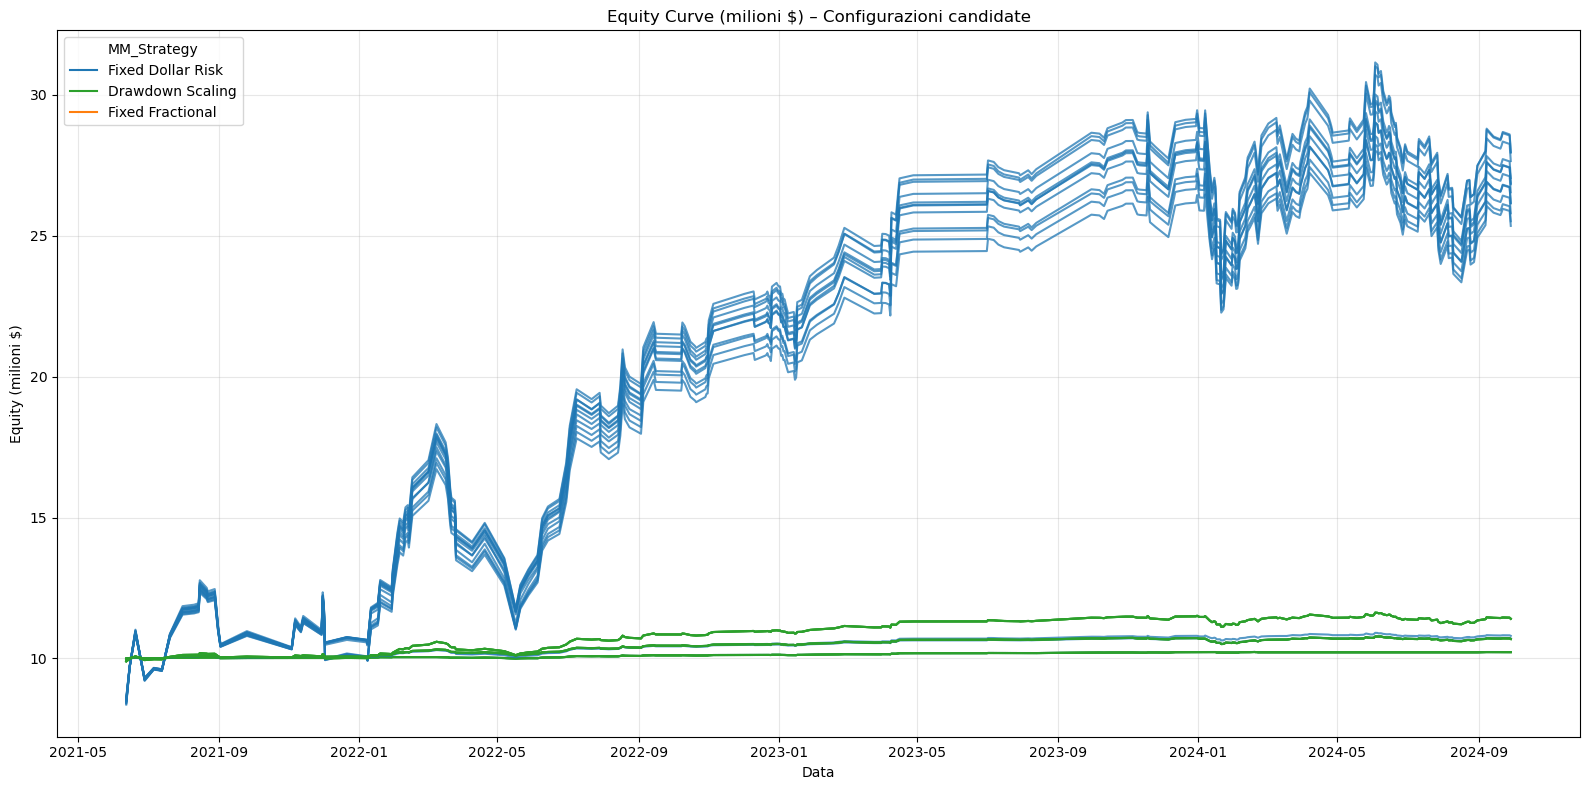

In [ ]:
import matplotlib.pyplot as plt

color_map = {
    "Fixed Dollar Risk": "#1f77b4",
    "Drawdown Scaling" : "#2ca02c",
    "Fixed Fractional" : "#ff7f0e"
}

plt.figure(figsize=(16, 8))
for row in work.itertuples():
    mm_param_tuple = tuple(sorted(row.MM_Param.items()))
    key = (row.Strategy_ID, row.MM_Strategy, mm_param_tuple)
    i = lookup_dict.get(key)
    if i is None:
        continue
    df_eq = detailed_trades[i]
    col = "Equity_Curve" if "Equity_Curve" in df_eq.columns else "Equity"
    if col not in df_eq:
        continue
    plt.plot(df_eq["Entry_Date"], df_eq[col]/1e6, alpha=0.75, color=color_map.get(row.MM_Strategy, "gray"))

# legenda per MM_Strategy
for mm, c in color_map.items():
    plt.plot([], [], color=c, label=mm)
plt.legend(title="MM_Strategy")
plt.title("Equity Curve (milioni $) – Configurazioni candidate")
plt.xlabel("Data")
plt.ylabel("Equity (milioni $)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

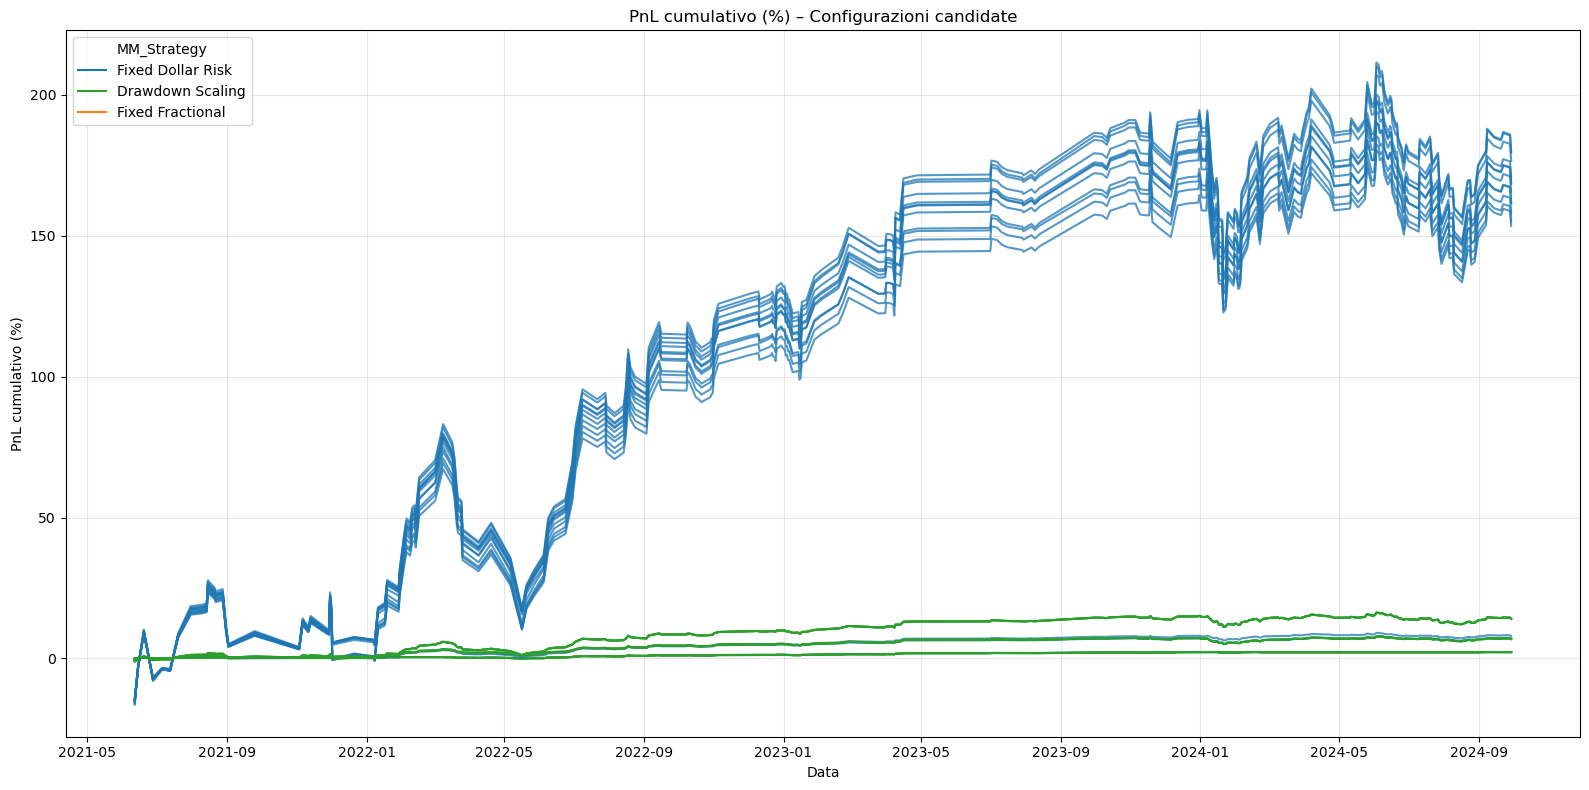

In [ ]:
plt.figure(figsize=(16, 8))
for row in work.itertuples():
    mm_param_tuple = tuple(sorted(row.MM_Param.items()))
    key = (row.Strategy_ID, row.MM_Strategy, mm_param_tuple)
    i = lookup_dict.get(key)
    if i is None:
        continue
    df_eq = detailed_trades[i]
    col = "Equity_Curve" if "Equity_Curve" in df_eq.columns else "Equity"
    if col not in df_eq:
        continue
    eq = df_eq[col].values.astype(float)
    pnl_pct = (eq/START_EQ - 1.0)*100.0
    plt.plot(df_eq["Entry_Date"], pnl_pct, alpha=0.75, color=color_map.get(row.MM_Strategy, "gray"))

for mm, c in color_map.items():
    plt.plot([], [], color=c, label=mm)
plt.legend(title="MM_Strategy")
plt.title("PnL cumulativo (%) – Configurazioni candidate")
plt.xlabel("Data")
plt.ylabel("PnL cumulativo (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

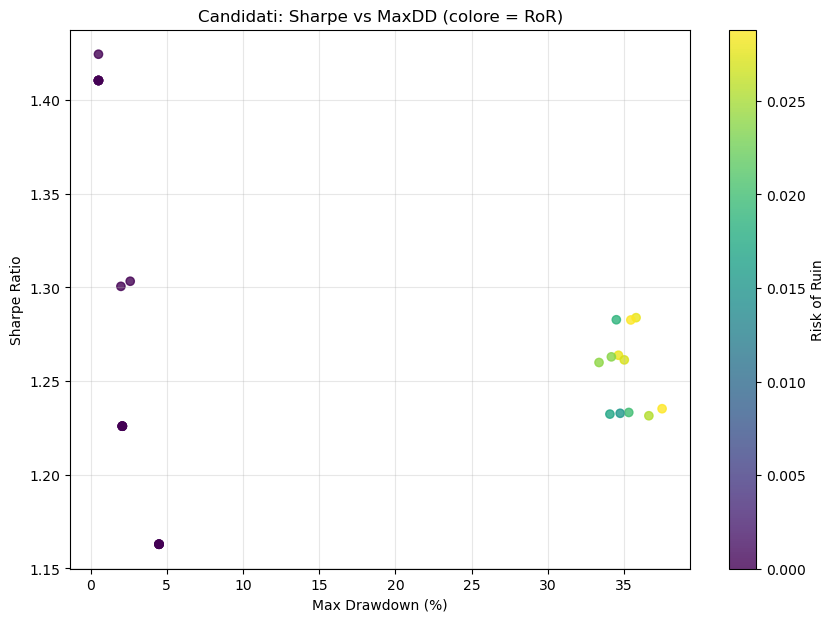

In [ ]:
import matplotlib.pyplot as plt

x = df_candidates_eval["Max_Drawdown_Pct"]*100
y = df_candidates_eval["Sharpe_Ratio"]
c = df_candidates_eval["Risk_of_Ruin"]

plt.figure(figsize=(10,7))
sc = plt.scatter(x, y, c=c, cmap="viridis", alpha=0.8)
plt.colorbar(sc, label="Risk of Ruin")
plt.xlabel("Max Drawdown (%)")
plt.ylabel("Sharpe Ratio")
plt.title("Candidati: Sharpe vs MaxDD (colore = RoR)")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
import pandas as pd
import numpy as np

POOL = candidates_strict.copy()   # oppure: candidates

def get_param(row, key):
    try:
        return row["MM_Param"].get(key, np.nan)
    except Exception:
        return np.nan

# 1) Selezioni
ds_final = (
    POOL[POOL["MM_Strategy"]=="Drawdown Scaling"]
    .sort_values(["Sharpe_Ratio","Risk_of_Ruin","Max_Drawdown_Pct"], ascending=[False,True,True])
    .head(1)
)

fdr_pool = POOL[POOL["MM_Strategy"]=="Fixed Dollar Risk"].copy()
if not fdr_pool.empty:
    fdr_pool["dollar_risk"] = fdr_pool.apply(lambda r: get_param(r, "dollar_risk"), axis=1)
    fdr_low = fdr_pool.sort_values(["dollar_risk","Risk_of_Ruin","Max_Drawdown_Pct"]).head(1)
    med = fdr_pool["dollar_risk"].median()
    fdr_mid = fdr_pool.iloc[(fdr_pool["dollar_risk"]-med).abs().argsort()].head(1)
else:
    fdr_low = pd.DataFrame([])
    fdr_mid = pd.DataFrame([])

tmp = pd.concat([ds_final, fdr_low, fdr_mid], ignore_index=True)

# 2) Chiave hashable per i parametri
tmp["MM_Param_key"] = tmp["MM_Param"].apply(
    lambda d: tuple(sorted(d.items())) if isinstance(d, dict) else d
)

# 3) Dedup su Strategy + MM + Param_key
finalists = (
    tmp.drop_duplicates(subset=["Strategy_ID","MM_Strategy","MM_Param_key"])
       .drop(columns=["MM_Param_key"])
       .reset_index(drop=True)
)

print("Finalisti selezionati:")
print(finalists[["Strategy_ID","MM_Strategy","MM_Param","Sharpe_Ratio","CAGR","Max_Drawdown_Pct","Risk_of_Ruin"]])

Finalisti selezionati:
          Strategy_ID        MM_Strategy  \
0  (0.03, 2.5, 0.011)   Drawdown Scaling   
1  (0.03, 2.5, 0.011)  Fixed Dollar Risk   
2  (0.03, 2.0, 0.011)  Fixed Dollar Risk   

                                            MM_Param  Sharpe_Ratio      CAGR  \
0  {'drawdown_pct': 0.05, 'max_drawdown_pct': 0.0...      1.410434  0.006729   
1                             {'dollar_risk': 50000}      1.424453  0.006791   
2                            {'dollar_risk': 100000}      1.300570  0.021976   

   Max_Drawdown_Pct  Risk_of_Ruin  
0          0.005134           0.0  
1          0.005134           0.0  
2          0.019869           0.0  


In [3]:
import pandas as pd
df_summary = pd.read_csv("Data/df_summary.csv")

In [4]:
#detailed_trades = pd.read_parquet("Data/detailed_trades.parquet")
final_detailed_trades = pd.read_csv("Data/final_detailed_trades.csv")

In [5]:
import ast
import numpy as np
import pandas as pd

# =========================
# 1) FILTRI HARD (prop-style)
# =========================

START_EQUITY = 10_000_000
MAX_DRAWDOWN = 0.30
MAX_RISK_OF_RUIN = 0.02
MIN_SHARPE = 0.50
WINRATE_MIN, WINRATE_MAX = 0.40, 0.80
MAX_CONSEC_LOSSES = 15
MAX_RISK_PCT = 0.02
MAX_FDR_RISK_PCT = 0.05

def _to_dict(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except Exception:
            return {}
    return {}

def _param_key(val):
    """Restituisce una chiave hashable e normalizzata per i parametri MM."""
    try:
        parsed = _to_dict(val)
    except Exception:
        parsed = val

    def _normalize(obj):
        if isinstance(obj, dict):
            cleaned = {k: _normalize(v) for k, v in obj.items() if v not in (None, [], {})}
            return tuple((k, cleaned[k]) for k in sorted(cleaned))
        if isinstance(obj, (list, tuple, set)):
            return tuple(_normalize(v) for v in obj)
        return obj

    if isinstance(parsed, dict):
        return _normalize(parsed)
    if isinstance(val, str):
        return val
    return _normalize(parsed)



def _percent_like_to_unit(s: pd.Series) -> pd.Series:
    s = pd.to_numeric(s, errors="coerce")
    non_na = s.dropna()
    if non_na.empty:
        return s
    if ((non_na > 1.0) & (non_na <= 100.0)).mean() > 0.5:
        return s / 100.0
    return s

# --- Prepara colonne comode
df_summary = df_summary.copy()
_mm = df_summary["MM_Param"].apply(_to_dict)
df_summary["dollar_risk"] = _mm.apply(lambda d: d.get("dollar_risk", np.nan))
df_summary["risk_pct"]    = _mm.apply(lambda d: d.get("risk_pct", np.nan))
df_summary["vol_target"]  = _mm.apply(lambda d: d.get("vol_target", np.nan))
df_summary["drawdown_pct"] = _mm.apply(lambda d: d.get("drawdown_pct", np.nan))

for col in ["Max_Drawdown_Pct","Risk_of_Ruin","Win_Rate"]:
    if col in df_summary.columns:
        df_summary[col] = _percent_like_to_unit(df_summary[col])

is_fdr = df_summary["MM_Strategy"].astype(str).eq("Fixed Dollar Risk")
is_ff  = df_summary["MM_Strategy"].astype(str).eq("Fixed Fractional")
is_vt  = df_summary["MM_Strategy"].astype(str).eq("Volatility Targeting")
is_dds = df_summary["MM_Strategy"].astype(str).eq("Drawdown Scaling")

# --- Hard masks
mask_notna   = df_summary[["Sharpe_Ratio","CAGR","Max_Drawdown_Pct","Risk_of_Ruin","Win_Rate"]].notna().all(axis=1)
mask_sharpe  = df_summary["Sharpe_Ratio"] >= MIN_SHARPE
mask_cagr    = df_summary["CAGR"].fillna(-np.inf) >= 0.0
mask_dd      = df_summary["Max_Drawdown_Pct"] <= MAX_DRAWDOWN
mask_ror     = df_summary["Risk_of_Ruin"] <= MAX_RISK_OF_RUIN
mask_wr      = df_summary["Win_Rate"].between(WINRATE_MIN, WINRATE_MAX)
mask_finaleq = df_summary["Final_Equity"] >= START_EQUITY
mask_streak  = df_summary["Max_Consecutive_Losses"].fillna(np.inf) <= MAX_CONSEC_LOSSES

dollar_risk   = pd.to_numeric(df_summary["dollar_risk"], errors="coerce")
risk_pct      = pd.to_numeric(df_summary["risk_pct"], errors="coerce")
vol_target    = pd.to_numeric(df_summary["vol_target"], errors="coerce")
drawdown_pct  = pd.to_numeric(df_summary["drawdown_pct"], errors="coerce")

mask_cap_le_eq  = ~(is_fdr & (dollar_risk > START_EQUITY))
mask_cap_pct_ok = ~(is_fdr & (dollar_risk > MAX_FDR_RISK_PCT * START_EQUITY))
mask_fdr_ok     = ~(is_fdr & (dollar_risk <= 50_000) | (dollar_risk >= 200_000))
mask_riskpct_ok = ~(is_ff & (risk_pct > MAX_RISK_PCT))
mask_vol_ok     = ~(is_vt & ((vol_target < 0.01) | (vol_target > 0.3)))
mask_dds_ok     = ~(is_dds & (drawdown_pct > 0.3))

mask_hard = (
    mask_notna & mask_sharpe & mask_cagr & mask_dd & mask_ror & mask_wr &
    mask_finaleq & mask_streak & mask_cap_le_eq & mask_cap_pct_ok &
    mask_fdr_ok & mask_riskpct_ok & mask_vol_ok & mask_dds_ok
)

df_hard_ok = df_summary.loc[mask_hard].copy()

print(f"[HARD FILTER] scartate {len(df_summary)-len(df_hard_ok)} su {len(df_summary)} strategie "
      f"(restano {len(df_hard_ok)}).")

# Normalizza la colonna Strategy_ID in df_hard_ok
df_hard_ok["Strategy_ID"] = df_hard_ok["Strategy_ID"].astype(str).str.replace(" ", "")

# Definisci i target nello stesso formato
TARGET_SIDS = [
    "(0.03,1.5,0.011)",
    "(0.03,2.0,0.011)",
    "(0.03,2.5,0.011)",
]

# Check se ora li trova
for sid in TARGET_SIDS:
    count = (df_hard_ok["Strategy_ID"] == sid).sum()
    print(f"SID {sid}: {count} strategie trovate")

# =========================
# 2) SCORE COMPOSITO (con Calmar)
# =========================

df_hard_ok["Calmar"] = df_hard_ok["CAGR"] / df_hard_ok["Max_Drawdown_Pct"].replace(0, np.nan)

BENEFIT_METRICS = ["Sharpe_Ratio","CAGR","Calmar"]
COST_METRICS    = ["Max_Drawdown_Pct","Risk_of_Ruin","Max_Consecutive_Losses"]

DEFAULT_WEIGHTS = {
    "Sharpe_Ratio": 0.20,
    "CAGR": 0.30,
    "Calmar": 0.30,
    "Max_Drawdown_Pct": 0.10,
    "Risk_of_Ruin": 0.10,
}

def zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    return (s - s.mean())/s.std(ddof=0) if s.std(ddof=0) > 0 else pd.Series(0, index=s.index)

df_scored = df_hard_ok.copy()
for m in BENEFIT_METRICS:
    df_scored[f"norm_{m}"] = zscore(df_scored[m])
for m in COST_METRICS:
    df_scored[f"norm_{m}"] = zscore(-df_scored[m])

w = DEFAULT_WEIGHTS
df_scored["Robustness_Score"] = sum(df_scored[f"norm_{m}"]*w[m] for m in w if f"norm_{m}" in df_scored)

# =========================
# 3) CLASSIFICHE PER FAMIGLIA + FINALE
# =========================

TOP_PER_SID = 3
ONE_PER_MM  = True

per_sid_best = []
for sid in TARGET_SIDS:
    sid_df = df_scored[df_scored["Strategy_ID"] == sid].copy()
    if sid_df.empty:
        print(f"[WARN] Nessuna strategia per SID={sid}")
        continue
    sid_df = sid_df.sort_values("Robustness_Score", ascending=False)
    if ONE_PER_MM:
        sid_df = sid_df.drop_duplicates(subset=["MM_Strategy"], keep="first")
    sid_best = sid_df.head(TOP_PER_SID).copy()
    sid_best["Local_Rank_in_SID"] = range(1, len(sid_best) + 1)
    sid_best["CAGR%"] = sid_best["CAGR"] * 100
    sid_best["MaxDD%"] = sid_best["Max_Drawdown_Pct"] * 100
    sid_best["RoR%"] = sid_best["Risk_of_Ruin"] * 100
    per_sid_best.append(sid_best)
    print(f"\n[SID {sid}] Top {len(sid_best)} strategie:")
    print(sid_best[["Strategy_ID","MM_Strategy","MM_Param","Sharpe_Ratio",
                   "CAGR%","MaxDD%","RoR%","Calmar","Robustness_Score"]])

if per_sid_best:
    pool = pd.concat(per_sid_best, ignore_index=True)
    final_rank = pool.sort_values("Robustness_Score", ascending=False).reset_index(drop=True)
    final_rank["Final_Rank"] = range(1, len(final_rank) + 1)
    final_rank["CAGR%"] = final_rank["CAGR"] * 100
    final_rank["MaxDD%"] = final_rank["Max_Drawdown_Pct"] * 100
    final_rank["RoR%"] = final_rank["Risk_of_Ruin"] * 100
    print("\n=== CLASSIFICA FINALE ===")
    print(final_rank[["Final_Rank","Strategy_ID","MM_Strategy","MM_Param",
                      "Sharpe_Ratio","CAGR%","MaxDD%","RoR%",
                      "Calmar","Robustness_Score"]])
else:
    print("Nessuna strategia sopravvissuta ai filtri.")


[HARD FILTER] scartate 38235 su 38760 strategie (restano 525).
SID (0.03,1.5,0.011): 153 strategie trovate
SID (0.03,2.0,0.011): 170 strategie trovate
SID (0.03,2.5,0.011): 202 strategie trovate

[SID (0.03,1.5,0.011)] Top 3 strategie:
            Strategy_ID        MM_Strategy  \
15835  (0.03,1.5,0.011)   Drawdown Scaling   
13623  (0.03,1.5,0.011)  Fixed Dollar Risk   
12922  (0.03,1.5,0.011)   Fixed Fractional   

                                                MM_Param  Sharpe_Ratio  \
15835  {'drawdown_pct': 0.15000000000000002, 'max_dra...      1.093777   
13623                            {'dollar_risk': 150000}      1.198605   
12922                                {'risk_pct': 0.015}      1.162950   

           CAGR%     MaxDD%  RoR%    Calmar  Robustness_Score  
15835  20.997249  21.219849  0.09  0.989510          0.666656  
13623   4.204661   4.346119  0.00  0.967452          0.288013  
12922   4.399770   4.488115  0.00  0.980316          0.278908  

[SID (0.03,2.0,0.011)] To

In [6]:
# =========================
# 4) CLUSTER: Conservative vs Aggressive
# =========================

# Soglie definite in stile prop
DD_CONSERVATIVE = 0.15   # 15%
DD_MAX = 0.30            # 30% (già usato come hard filter sopra)

conservative = final_rank[final_rank["Max_Drawdown_Pct"] <= DD_CONSERVATIVE].copy()
aggressive   = final_rank[(final_rank["Max_Drawdown_Pct"] > DD_CONSERVATIVE) &
                          (final_rank["Max_Drawdown_Pct"] <= DD_MAX)].copy()

print("\n=== STRATEGIE CONSERVATIVE (MaxDD <= 15%) ===")
if conservative.empty:
    print("Nessuna strategia in questo cluster.")
else:
    print(conservative[["Final_Rank","Strategy_ID","MM_Strategy","MM_Param",
                        "Sharpe_Ratio","CAGR%","MaxDD%","RoR%","Calmar","Robustness_Score"]])

print("\n=== STRATEGIE AGGRESSIVE (15% < MaxDD <= 30%) ===")
if aggressive.empty:
    print("Nessuna strategia in questo cluster.")
else:
    print(aggressive[["Final_Rank","Strategy_ID","MM_Strategy","MM_Param",
                      "Sharpe_Ratio","CAGR%","MaxDD%","RoR%","Calmar","Robustness_Score"]])



=== STRATEGIE CONSERVATIVE (MaxDD <= 15%) ===
   Final_Rank       Strategy_ID        MM_Strategy                 MM_Param  \
2           3  (0.03,2.0,0.011)  Fixed Dollar Risk  {'dollar_risk': 100000}   
4           5  (0.03,2.5,0.011)  Fixed Dollar Risk  {'dollar_risk': 150000}   
5           6  (0.03,2.0,0.011)   Fixed Fractional       {'risk_pct': 0.01}   
6           7  (0.03,1.5,0.011)  Fixed Dollar Risk  {'dollar_risk': 150000}   
7           8  (0.03,2.5,0.011)   Fixed Fractional       {'risk_pct': 0.02}   
8           9  (0.03,1.5,0.011)   Fixed Fractional      {'risk_pct': 0.015}   

   Sharpe_Ratio     CAGR%    MaxDD%  RoR%    Calmar  Robustness_Score  
2      1.300570  2.197577  1.986860   0.0  1.106055          0.574764  
4      1.303300  2.579430  2.596942   0.0  0.993257          0.395730  
5      1.225958  2.147900  2.077685   0.0  1.033795          0.372953  
6      1.198605  4.204661  4.346119   0.0  0.967452          0.288013  
7      1.171458  3.465822  3.499911   0

In [7]:
# ================================================================
# COSTRUZIONE DEL DATAFRAME `final_detailed_trades` (solo documentazione)
# ================================================================
# Questo blocco serve a costruire final_detailed_trades a partire da
# detailed_trades e final_rank. È pesante in RAM, quindi lo lasciamo commentato.
# Se necessario, decommentare ed eseguire una tantum.

"""
import json
import pandas as pd
import numpy as np

final_detailed_list = []

def clean_param_dict(param_str):
    try:
        if isinstance(param_str, str):
            try:
                return json.loads(param_str)
            except json.JSONDecodeError:
                return eval(param_str)
        return param_str
    except:
        return {}

def match_parameters(row_params, trade_params):
    if row_params.get('dollar_risk'):
        return trade_params.get('dollar_risk') == row_params['dollar_risk']
    elif row_params.get('risk_pct'):
        return trade_params.get('risk_pct') == row_params['risk_pct']
    elif 'drawdown_pct' in row_params:
        keys = ['drawdown_pct','max_drawdown_pct','base_risk_pct']
        return all(abs(trade_params.get(k, 0) - row_params.get(k, 0)) < 1e-10 for k in keys)
    return False

for _, row in final_rank.iterrows():
    sid = str(row["Strategy_ID"]).replace(" ", "")
    mm  = row["MM_Strategy"]
    params = clean_param_dict(row["MM_Param"])

    mask = (
        (detailed_trades["Strategy_ID"].str.replace(" ", "") == sid) &
        (detailed_trades["MM_Strategy"] == mm)
    )
    subset = detailed_trades.loc[mask].copy()

    if not subset.empty:
        subset["clean_params"] = subset["MM_Param"].apply(clean_param_dict)
        final_mask = subset["clean_params"].apply(lambda x: match_parameters(params, x))
        final_trades = subset.loc[final_mask].copy()

        if not final_trades.empty:
            final_trades["Final_Rank"] = row.get("Final_Rank", np.nan)
            final_detailed_list.append(final_trades)

if final_detailed_list:
    final_detailed_trades = pd.concat(final_detailed_list, ignore_index=True)
    final_detailed_trades.to_csv("/content/drive/MyDrive/BTC Project/Data/final_detailed_trades.csv", index=False)
    print(f"✅ final_detailed_trades creato e salvato con {len(final_detailed_trades)} righe")
else:
    print("⚠️ Nessuna trade trovata per le strategie selezionate")
"""


'\nimport json\nimport pandas as pd\nimport numpy as np\n\nfinal_detailed_list = []\n\ndef clean_param_dict(param_str):\n    try:\n        if isinstance(param_str, str):\n            try:\n                return json.loads(param_str)\n            except json.JSONDecodeError:\n                return eval(param_str)\n        return param_str\n    except:\n        return {}\n\ndef match_parameters(row_params, trade_params):\n    if row_params.get(\'dollar_risk\'):\n        return trade_params.get(\'dollar_risk\') == row_params[\'dollar_risk\']\n    elif row_params.get(\'risk_pct\'):\n        return trade_params.get(\'risk_pct\') == row_params[\'risk_pct\']\n    elif \'drawdown_pct\' in row_params:\n        keys = [\'drawdown_pct\',\'max_drawdown_pct\',\'base_risk_pct\']\n        return all(abs(trade_params.get(k, 0) - row_params.get(k, 0)) < 1e-10 for k in keys)\n    return False\n\nfor _, row in final_rank.iterrows():\n    sid = str(row["Strategy_ID"]).replace(" ", "")\n    mm  = row["MM

In [8]:
import pandas as pd
import json
# Import Plotly
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Colori e stili
colors_light = ["#e0bbff", "#d4a3ff", "#c38aff"]  # conservative
colors_dark  = ["#8b5fbf", "#6a359c", "#4b0082"]  # aggressive
line_styles = ['solid', 'dash', 'dot', 'dashdot']

# Plot delle equity curves su due subplot con Plotly
fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=["Conservative Strategies (MaxDD ≤ 15%)", "Aggressive Strategies (15% < MaxDD ≤ 30%)"],
    shared_xaxes=True
)

def plot_from_final(fig, row_idx, strategies_df, trades_df, colors, line_styles):
    for i, row in strategies_df.iterrows():
        sid = str(row["Strategy_ID"]).replace(" ", "")
        mm = row["MM_Strategy"]

        # subset diretto da final_detailed_trades
        subset = trades_df[
            (trades_df["Strategy_ID"].str.replace(" ", "", regex=False) == sid) &
            (trades_df["MM_Strategy"] == mm)
        ].copy()

        if subset.empty:
            continue

        label = f"{sid} | {mm}"
        fig.add_trace(
            go.Scatter(
                x=pd.to_datetime(subset["Entry_Date"]),
                y=subset["Equity_Curve"]/1e6,
                mode='lines',
                name=label,
                line=dict(
                    color=colors[i % len(colors)],
                    dash=line_styles[(i//len(colors)) % len(line_styles)],
                    width=1.5
                )
            ),
            row=row_idx, col=1
        )

def clean_param_dict(param_str):
    try:
        if isinstance(param_str, str):
            try:
                return json.loads(param_str)
            except json.JSONDecodeError:
                return eval(param_str)
        return param_str
    except:
        return {}

# Conservative
plot_from_final(fig, 1, conservative, final_detailed_trades, colors_light, line_styles)

# Aggressive
plot_from_final(fig, 2, aggressive, final_detailed_trades, colors_dark, line_styles)

# Layout
fig.update_layout(
    height=800, width=1000,
    title_text="Equity Curves by Cluster (from final_detailed_trades)",
    showlegend=True,
    legend=dict(x=1.02, y=1, bordercolor="#666666", borderwidth=0.5, font=dict(color="#ffffff")),
    template="plotly_dark",
    paper_bgcolor="#202020",
    plot_bgcolor="#202020",
    font=dict(color="#ffffff"),
    hovermode="x unified"
)
fig.update_xaxes(gridcolor="#666666", showspikes=True, spikemode='across', spikesnap='cursor', spikedash='solid', spikecolor="#ffffff", spikethickness=1)
fig.update_yaxes(gridcolor="#666666")
fig.show()


In [9]:
# === Applica fees & slippage SOLO alle strategie robuste (final_detailed_trades) ===
import numpy as np
import pandas as pd

# ---- Parametri costi (modificabili) ----
START_EQUITY   = 10_000_000        # equity iniziale
TAKER_FEE_PCT  = 0.0005            # 0.05% per lato (taker) su Deribit
SLIPPAGE_USD   = 2.0               # USD per lato (ingresso+uscita) per contratto

def _best_time_col(df: pd.DataFrame) -> str:
    cand = [c for c in ("Exit_Timestamp", "Entry_Timestamp", "Exit_Date", "Entry_Date") if c in df.columns]
    nn = {c: df[c].notna().sum() for c in cand}
    return max(nn, key=nn.get)

# Normalizza chiavi per raggruppare correttamente
final_detailed_trades = final_detailed_trades.copy()
final_detailed_trades["Strategy_ID"] = final_detailed_trades["Strategy_ID"].astype(str).str.replace(" ", "", regex=False)
final_detailed_trades["_mm_param_dict"] = final_detailed_trades["MM_Param"].apply(clean_param_dict)

# Costruiamo un _sel_key coerente
final_detailed_trades["_sel_key"] = (
    final_detailed_trades["Strategy_ID"].astype(str) + "|" +
    final_detailed_trades["MM_Strategy"].astype(str) + "|" +
    final_detailed_trades["_mm_param_dict"].astype(str)
)

def _apply_costs_to_trades(trades_sub: pd.DataFrame,
                           taker_fee_pct: float = TAKER_FEE_PCT,
                           slippage_usd: float = SLIPPAGE_USD,
                           start_equity: float = START_EQUITY) -> pd.DataFrame:
    """Applica fee & slippage e ricostruisce Equity_Curve_net per ciascuna strategia selezionata."""
    if trades_sub.empty:
        return trades_sub.assign(**{
            "Equity_Curve_net": np.nan,
            "Fees_USD": np.nan,
            "Slippage_USD": np.nan,
            "Return_USD_net": np.nan,
            "Return_Pct_net": np.nan
        })

    time_col = _best_time_col(trades_sub)
    out = []
    for key, g in trades_sub.sort_values(time_col).groupby("_sel_key", sort=False):
        g = g.copy()
        contracts = pd.to_numeric(g.get("Contracts", 1.0), errors="coerce").fillna(1.0).abs()

        eq = pd.to_numeric(g["Equity_Curve"], errors="coerce")
        eq_prev = eq.shift(1)
        eq_prev.iloc[0] = start_equity
        eq_prev = eq_prev.ffill()

        ret_usd = (eq - eq_prev).fillna(0.0)

        notional_entry = (pd.to_numeric(g["Spot_Entry"], errors="coerce").abs() * contracts)
        notional_exit  = (pd.to_numeric(g["Spot_Exit"],  errors="coerce").abs() * contracts)
        fees_usd = taker_fee_pct * (notional_entry + notional_exit)

        slp_usd = slippage_usd * contracts * 2.0

        ret_usd_net = ret_usd - fees_usd - slp_usd
        eq_net = start_equity + ret_usd_net.cumsum()
        eq_net_prev = eq_net.shift(1).fillna(start_equity)

        with np.errstate(divide='ignore', invalid='ignore'):
            ret_pct_net = 100.0 * ((eq_net - eq_net_prev) / eq_net_prev.replace(0.0, np.nan))
            ret_pct_net = ret_pct_net.replace([np.inf, -np.inf], np.nan).fillna(0.0)

        g["Fees_USD"]         = fees_usd.to_numpy()
        g["Slippage_USD"]     = slp_usd.to_numpy()
        g["Equity_Curve_net"] = eq_net.to_numpy()
        g["Return_USD_net"]   = ret_usd_net.to_numpy()
        g["Return_Pct_net"]   = ret_pct_net.to_numpy()

        out.append(g)

    return pd.concat(out, ignore_index=True)

# ---- Applicazione su final_detailed_trades ----
cons_trades_net = _apply_costs_to_trades(
    final_detailed_trades[final_detailed_trades["Final_Rank"].isin(conservative["Final_Rank"])]
)

aggr_trades_net = _apply_costs_to_trades(
    final_detailed_trades[final_detailed_trades["Final_Rank"].isin(aggressive["Final_Rank"])]
)

def _quick_summary(df):
    if df.empty:
        return {"n_trades": 0, "n_strategies": 0}
    return {
        "n_trades": len(df),
        "n_strategies": df["_sel_key"].nunique(),
        "min_date": pd.to_datetime(df[_best_time_col(df)]).min(),
        "max_date": pd.to_datetime(df[_best_time_col(df)]).max(),
    }

print("[APPLY COSTS] Conservative ->", _quick_summary(cons_trades_net))
print("[APPLY COSTS] Aggressive  ->", _quick_summary(aggr_trades_net))


[APPLY COSTS] Conservative -> {'n_trades': 1506, 'n_strategies': 6, 'min_date': Timestamp('2021-06-13 23:55:00'), 'max_date': Timestamp('2024-09-30 22:00:00')}
[APPLY COSTS] Aggressive  -> {'n_trades': 753, 'n_strategies': 3, 'min_date': Timestamp('2021-06-13 23:55:00'), 'max_date': Timestamp('2024-09-30 22:00:00')}


In [10]:
# === Equity curves post costi (fees + slippage) ===
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig_net = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=[
        "Conservative Strategies – Net Equity",
        "Aggressive Strategies – Net Equity",
    ],
    shared_xaxes=True,
)


def _plot_net_equity(fig, row_idx, strategies_df, trades_df, colors, line_styles):
    for i, row in strategies_df.iterrows():
        sid = str(row["Strategy_ID"]).replace(" ", "")
        mm_name = row["MM_Strategy"]

        subset = trades_df[
            (trades_df["Strategy_ID"].astype(str).str.replace(" ", "", regex=False) == sid)
            & (trades_df["MM_Strategy"] == mm_name)
        ].copy()

        if subset.empty:
            continue

        time_col = _best_time_col(subset)
        subset = subset.sort_values(time_col)

        fig.add_trace(
            go.Scatter(
                x=pd.to_datetime(subset[time_col]),
                y=subset["Equity_Curve_net"] / 1e6,
                mode="lines",
                name=f"{sid} | {mm_name}",
                legendgroup=f"{sid}_{mm_name}",
                line=dict(
                    color=colors[i % len(colors)],
                    dash=line_styles[(i // len(colors)) % len(line_styles)],
                    width=1.5,
                ),
            ),
            row=row_idx,
            col=1,
        )


_plot_net_equity(fig_net, 1, conservative, cons_trades_net, colors_light, line_styles)
_plot_net_equity(fig_net, 2, aggressive, aggr_trades_net, colors_dark, line_styles)

fig_net.update_layout(
    height=800,
    width=1000,
    title_text="Equity Curves After Fees & Slippage (Millions USD)",
    showlegend=True,
    legend=dict(x=1.02, y=1, bordercolor="#666666", borderwidth=0.5, font=dict(color="#ffffff")),
    hovermode="x unified",
    template="plotly_dark",
    paper_bgcolor="#202020",
    plot_bgcolor="#202020",
    font=dict(color="#ffffff")
)

fig_net.update_yaxes(title_text="Equity (USD millions)", row=1, col=1, gridcolor="#666666")
fig_net.update_yaxes(title_text="Equity (USD millions)", row=2, col=1, gridcolor="#666666")
fig_net.update_xaxes(gridcolor="#666666", row=1, col=1, showspikes=True, spikemode='across', spikesnap='cursor', spikedash='solid', spikecolor="#ffffff", spikethickness=1)
fig_net.update_xaxes(title_text="Date", row=2, col=1, gridcolor="#666666", showspikes=True, spikemode='across', spikesnap='cursor', spikedash='solid', spikecolor="#ffffff", spikethickness=1)

fig_net.show()


In [15]:
# === Risk of Ruin netto (post costi) ===
from joblib import Parallel, delayed
import pandas as pd

if 'compute_ror_from_equity' not in globals():
    raise RuntimeError("compute_ror_from_equity non è definita: riesegui la cella che la dichiara prima di calcolare l'RoR netto.")

id_cols = ["Strategy_ID", "MM_Strategy", "MM_Param", "Final_Rank", "Cluster"]


if '_stringify_param' not in globals():
    def _stringify_param(val):
        return val if isinstance(val, str) else repr(val)

def _prepare_net_groups(trades_df: pd.DataFrame, cluster_name: str) -> list[dict]:
    groups = []
    if trades_df is None or trades_df.empty:
        return groups

    time_col = _best_time_col(trades_df)
    for _, grp in trades_df.sort_values(time_col).groupby("_sel_key", sort=False):
        eq = pd.to_numeric(grp["Equity_Curve_net"], errors="coerce").ffill().bfill()
        if eq.isna().all() or len(eq) < 10:
            continue

        rank_val = grp["Final_Rank"].iloc[0] if "Final_Rank" in grp else pd.NA
        if pd.notna(rank_val):
            try:
                rank_val = int(rank_val)
            except (TypeError, ValueError):
                pass

        groups.append({
            "equity_curve": eq.to_numpy(),
            "Strategy_ID": str(grp["Strategy_ID"].iloc[0]).replace(" ", ""),
            "MM_Strategy": grp["MM_Strategy"].iloc[0],
            "MM_Param": grp["MM_Param"].iloc[0],
            "Final_Rank": rank_val,
            "Cluster": cluster_name,
        })

    return groups


def _ror_net_worker(info: dict) -> dict:
    df_equity = pd.DataFrame({"Equity_Curve": info["equity_curve"]})
    ror = compute_ror_from_equity(df_equity)

    out = {k: v for k, v in info.items() if k != "equity_curve"}
    out["Risk_of_Ruin_net"] = ror
    return out


group_jobs = _prepare_net_groups(cons_trades_net, "Conservative") + _prepare_net_groups(aggr_trades_net, "Aggressive")

if not group_jobs:
    print("⚠️ Nessuna strategia disponibile per il calcolo del Risk of Ruin netto.")
    net_ror_df = pd.DataFrame(columns=id_cols + ["Risk_of_Ruin_net"])
else:
    net_ror_results = Parallel(n_jobs=-1, backend="loky")(
        delayed(_ror_net_worker)(info)
        for info in group_jobs
    )
    net_ror_df = pd.DataFrame(net_ror_results)

if not net_ror_df.empty:
    net_ror_df["Final_Rank"] = pd.to_numeric(net_ror_df["Final_Rank"], errors="coerce").astype("Int64")
    net_ror_df["Strategy_ID"] = net_ror_df["Strategy_ID"].astype(str).str.replace(" ", "", regex=False)
    net_ror_df['Param_Key'] = net_ror_df['MM_Param'].map(_param_key)

    if "comparison_metrics" in globals():
        if 'Param_Key' not in comparison_metrics.columns:
            comparison_metrics['Param_Key'] = comparison_metrics['MM_Param'].map(_param_key)
        comparison_metrics["Strategy_ID"] = comparison_metrics["Strategy_ID"].astype(str).str.replace(" ", "", regex=False)
        net_ror_df_cols = net_ror_df[['Strategy_ID','MM_Strategy','Param_Key','Final_Rank','Cluster','Risk_of_Ruin_net']].copy()
        comparison_metrics = comparison_metrics.merge(net_ror_df_cols, on=['Strategy_ID','MM_Strategy','Param_Key','Final_Rank','Cluster'], how='left')
        if "Risk_of_Ruin" in comparison_metrics.columns:
            comparison_metrics = comparison_metrics.rename(columns={"Risk_of_Ruin": "Risk_of_Ruin_gross"})
        elif 'Risk_of_Ruin_gross' not in comparison_metrics.columns and 'df_summary' in globals():
            df_ror_gross = df_summary[['Strategy_ID','MM_Strategy','MM_Param','Risk_of_Ruin']].copy()
            df_ror_gross = df_ror_gross.rename(columns={'Risk_of_Ruin': 'Risk_of_Ruin_gross'})
            df_ror_gross['Strategy_ID'] = df_ror_gross['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)
            df_ror_gross['Param_Key'] = df_ror_gross['MM_Param'].map(_param_key)
            df_ror_gross['MM_Param'] = df_ror_gross['MM_Param'].map(_stringify_param)
            comparison_metrics = comparison_metrics.merge(
                df_ror_gross[['Strategy_ID','MM_Strategy','Param_Key','Risk_of_Ruin_gross']],
                on=['Strategy_ID','MM_Strategy','Param_Key'],
                how='left'
            )

        if "Risk_of_Ruin_gross" in comparison_metrics.columns and "Risk_of_Ruin_net" in comparison_metrics.columns:
            comparison_metrics["Risk_of_Ruin_delta"] = comparison_metrics["Risk_of_Ruin_net"] - comparison_metrics["Risk_of_Ruin_gross"]

        display_cols = [
            "Final_Rank","Cluster","Strategy_ID","MM_Strategy","MM_Param",
            "Risk_of_Ruin_gross","Risk_of_Ruin_net","Risk_of_Ruin_delta"
        ]
        present_cols = [c for c in display_cols if c in comparison_metrics.columns]
        if present_cols:
            comparison_metrics[present_cols].sort_values(["Cluster","Final_Rank"])
    else:
        net_ror_df.sort_values(["Cluster","Final_Rank"])
else:
    print("⚠️ Nessuna strategia disponibile per il calcolo del Risk of Ruin netto.")


In [31]:
# === Metriche lorde vs nette post costi ===
def _compute_metrics(trades_df: pd.DataFrame,
                     cluster_name: str,
                     equity_col: str,
                     label: str,
                     include_costs: bool = False) -> pd.DataFrame:
    id_cols = ["Strategy_ID", "MM_Strategy", "MM_Param", "Final_Rank", "Cluster"]
    if trades_df is None or trades_df.empty:
        return pd.DataFrame(columns=id_cols)

    time_col = _best_time_col(trades_df)
    rows = []

    for _, grp in trades_df.sort_values(time_col).groupby("_sel_key", sort=False):
        if grp.empty:
            continue

        equity = pd.to_numeric(grp[equity_col], errors="coerce").ffill().bfill()
        if equity.isna().all():
            continue

        time_index = pd.to_datetime(grp[time_col])
        start_date = time_index.min()
        end_date = time_index.max()
        n_days = max((end_date - start_date).days, 0)
        n_trades = len(grp)
        trades_per_year = (n_trades / n_days) * 365 if n_days > 0 else 0

        eq_prev = equity.shift(1)
        eq_prev.iloc[0] = START_EQUITY
        eq_prev = eq_prev.ffill()

        ret_usd = (equity - eq_prev).fillna(0.0)
        returns = (ret_usd / eq_prev.replace(0.0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0.0)

        ret_mean = returns.mean()
        ret_std = returns.std(ddof=0)
        sharpe = (ret_mean / ret_std) * np.sqrt(trades_per_year) if ret_std > 0 and trades_per_year > 0 else 0.0

        peak = equity.cummax()
        drawdown_pct = (equity - peak) / peak.replace(0.0, np.nan)
        max_dd_pct = drawdown_pct.min()

        start_equity = eq_prev.iloc[0] if not eq_prev.empty else START_EQUITY
        final_equity = float(equity.iloc[-1])
        cumulative_return = (final_equity / start_equity) - 1 if start_equity else np.nan

        n_years = n_days / 365.25 if n_days > 0 else 0.0
        if n_years > 0 and final_equity > 0 and start_equity > 0:
            cagr = (final_equity / start_equity) ** (1 / n_years) - 1
        else:
            cagr = np.nan

        calmar = cagr / abs(max_dd_pct) if np.isfinite(cagr) and np.isfinite(max_dd_pct) and abs(max_dd_pct) > 0 else np.nan
        win_rate = (returns > 0).mean() if n_trades > 0 else np.nan
        losing_streak = max_consecutive_losses(returns)

        contracts = pd.to_numeric(grp.get("Contracts", 1.0), errors="coerce").abs()
        contracts = contracts.replace(0.0, np.nan).fillna(1.0)
        unit_pnl = (ret_usd / contracts).replace([np.inf, -np.inf], np.nan)
        avg_unit_pnl = unit_pnl.mean()

        rank_val = grp["Final_Rank"].iloc[0] if "Final_Rank" in grp else np.nan

        row = {
            "Strategy_ID": grp["Strategy_ID"].iloc[0],
            "MM_Strategy": grp["MM_Strategy"].iloc[0],
            "MM_Param": grp["MM_Param"].iloc[0],
            "Final_Rank": rank_val,
            "Cluster": cluster_name,
            "N_Trades": n_trades,
            "Trades_Per_Year": trades_per_year,
            "Sharpe_Ratio": sharpe,
            "CAGR": cagr,
            "Calmar": calmar,
            "Max_Drawdown_Pct": abs(max_dd_pct) if np.isfinite(max_dd_pct) else np.nan,
            "Cumulative_Return": cumulative_return,
            "Win_Rate": win_rate,
            "Max_Consecutive_Losses": losing_streak,
            "Final_Equity": final_equity,
            "Profit_USD": final_equity - start_equity,
            "Avg_Unit_PnL": avg_unit_pnl,
        }

        if include_costs:
            row["Total_Fees_USD"] = pd.to_numeric(grp["Fees_USD"], errors="coerce").fillna(0.0).sum()
            row["Total_Slippage_USD"] = pd.to_numeric(grp["Slippage_USD"], errors="coerce").fillna(0.0).sum()

        rows.append(row)

    if not rows:
        return pd.DataFrame(columns=id_cols)

    df_metrics = pd.DataFrame(rows)
    df_metrics["Final_Rank"] = pd.to_numeric(df_metrics["Final_Rank"], errors="coerce").astype("Int64")
    df_metrics = df_metrics.sort_values(["Cluster", "Final_Rank"]).reset_index(drop=True)

    metric_cols = [c for c in df_metrics.columns if c not in id_cols]
    if label:
        df_metrics = df_metrics.rename(columns={c: f"{c}_{label}" for c in metric_cols})

    return df_metrics


cons_trades_gross = final_detailed_trades[final_detailed_trades["Final_Rank"].isin(conservative["Final_Rank"])]
aggr_trades_gross = final_detailed_trades[final_detailed_trades["Final_Rank"].isin(aggressive["Final_Rank"])]

gross_metrics = pd.concat([
    _compute_metrics(cons_trades_gross, "Conservative", "Equity_Curve", label="gross"),
    _compute_metrics(aggr_trades_gross, "Aggressive", "Equity_Curve", label="gross"),
], ignore_index=True)

net_metrics = pd.concat([
    _compute_metrics(cons_trades_net, "Conservative", "Equity_Curve_net", label="net", include_costs=True),
    _compute_metrics(aggr_trades_net, "Aggressive", "Equity_Curve_net", label="net", include_costs=True),
], ignore_index=True)

id_cols = ["Strategy_ID", "MM_Strategy", "MM_Param", "Final_Rank", "Cluster"]
comparison_metrics = gross_metrics.merge(net_metrics, on=id_cols, how="outer")
comparison_metrics = comparison_metrics.sort_values(["Cluster", "Final_Rank"]).reset_index(drop=True)

metric_bases = [
    "N_Trades",
    "Trades_Per_Year",
    "Sharpe_Ratio",
    "CAGR",
    "Calmar",
    "Max_Drawdown_Pct",
    "Cumulative_Return",
    "Win_Rate",
    "Max_Consecutive_Losses",
    "Final_Equity",
    "Profit_USD",
    "Avg_Unit_PnL",
]

comparison_metrics['Param_Key'] = comparison_metrics['MM_Param'].map(_param_key)
comparison_metrics['Strategy_ID'] = comparison_metrics['Strategy_ID'].astype('string')
comparison_metrics['Strategy_ID'] = comparison_metrics['Strategy_ID'].str.replace(' ', '', regex=False)
id_cols_ror = ['Strategy_ID','MM_Strategy','Param_Key','Cluster']
comparison_metrics['MM_Param'] = comparison_metrics['MM_Param'].apply(lambda v: repr(v) if not isinstance(v, str) else v)
comparison_metrics['MM_Param'] = comparison_metrics['MM_Param'].astype('string')

def _stringify_param(val):
    if isinstance(val, str):
        return val
    return repr(val)

def _ror_from_cluster(df_cluster, cluster_name):
    if cluster_name is None or df_cluster is None:
        return pd.DataFrame()
    if df_cluster.empty:
        return pd.DataFrame()
    if not isinstance(df_cluster, pd.DataFrame):
        return pd.DataFrame()
    if {'Strategy_ID','MM_Strategy','MM_Param','Final_Rank'}.issubset(df_cluster.columns) is False:
        return pd.DataFrame()
    if 'Risk_of_Ruin' in df_cluster.columns:
        ror_series = pd.to_numeric(df_cluster['Risk_of_Ruin'], errors='coerce')
    elif 'RoR%' in df_cluster.columns:
        ror_series = pd.to_numeric(df_cluster['RoR%'], errors='coerce') / 100.0
    else:
        return pd.DataFrame()
    out = df_cluster[['Strategy_ID','MM_Strategy','MM_Param','Final_Rank']].copy()
    out['Risk_of_Ruin_gross'] = ror_series
    out['Cluster'] = cluster_name
    out['Param_Key'] = out['MM_Param'].map(_param_key)
    out['Strategy_ID'] = out['Strategy_ID'].astype('string').str.replace(' ', '', regex=False)
    out['MM_Param'] = out['MM_Param'].map(_stringify_param).astype('string')
    out['Final_Rank'] = pd.to_numeric(out['Final_Rank'], errors='coerce').astype('Int64')
    return out

gross_ror_sources = []
if 'conservative' in globals():
    gross_ror_sources.append(_ror_from_cluster(conservative, 'Conservative'))
if 'aggressive' in globals():
    gross_ror_sources.append(_ror_from_cluster(aggressive, 'Aggressive'))
gross_ror_sources = [df for df in gross_ror_sources if df is not None and not df.empty]
if gross_ror_sources:
    gross_ror_df = pd.concat(gross_ror_sources, ignore_index=True)
    gross_ror_df = gross_ror_df.drop_duplicates(id_cols_ror, keep='first')
    cols_keep = id_cols_ror + ['Risk_of_Ruin_gross']
    gross_ror_df = gross_ror_df[cols_keep]
    comparison_metrics = comparison_metrics.merge(gross_ror_df, on=id_cols_ror, how='left')

if 'net_ror_df' in globals() and isinstance(net_ror_df, pd.DataFrame) and not net_ror_df.empty:
    ror_cols = ['Strategy_ID','MM_Strategy','MM_Param','Final_Rank','Cluster','Risk_of_Ruin_net']
    available_cols = [c for c in ror_cols if c in net_ror_df.columns]
    if len(available_cols) == len(ror_cols):
        net_ror_tmp = net_ror_df[ror_cols].copy()
        net_ror_tmp['Strategy_ID'] = net_ror_tmp['Strategy_ID'].astype('string').str.replace(' ', '', regex=False)
        net_ror_tmp['Param_Key'] = net_ror_tmp['MM_Param'].map(_param_key)
        net_ror_tmp['MM_Param'] = net_ror_tmp['MM_Param'].map(_stringify_param).astype('string')
        net_ror_tmp['Final_Rank'] = pd.to_numeric(net_ror_tmp['Final_Rank'], errors='coerce').astype('Int64')
        cols_keep = id_cols_ror + ['Risk_of_Ruin_net']
        comparison_metrics = comparison_metrics.merge(net_ror_tmp[cols_keep], on=id_cols_ror, how='left')

if 'Risk_of_Ruin_gross' not in comparison_metrics.columns and 'Risk_of_Ruin' in comparison_metrics.columns:
    comparison_metrics = comparison_metrics.rename(columns={'Risk_of_Ruin': 'Risk_of_Ruin_gross'})

if 'Risk_of_Ruin_net' in comparison_metrics.columns and 'Risk_of_Ruin_gross' in comparison_metrics.columns:
    comparison_metrics['Risk_of_Ruin_delta'] = comparison_metrics['Risk_of_Ruin_net'] - comparison_metrics['Risk_of_Ruin_gross']

for base in metric_bases:
    gross_col = f"{base}_gross"
    net_col = f"{base}_net"
    if gross_col in comparison_metrics.columns and net_col in comparison_metrics.columns:
        comparison_metrics[f"{base}_delta"] = comparison_metrics[net_col] - comparison_metrics[gross_col]

cols_to_show = [
    "Final_Rank",
    "Cluster",
    "Strategy_ID",
    "MM_Strategy",
    "MM_Param",
    "N_Trades_gross",
    "N_Trades_net",
    "N_Trades_delta",
    "Trades_Per_Year_gross",
    "Trades_Per_Year_net",
    "Trades_Per_Year_delta",
    "Sharpe_Ratio_gross",
    "Sharpe_Ratio_net",
    "Sharpe_Ratio_delta",
    "CAGR_gross",
    "CAGR_net",
    "CAGR_delta",
    "Calmar_gross",
    "Calmar_net",
    "Calmar_delta",
    "Max_Drawdown_Pct_gross",
    "Max_Drawdown_Pct_net",
    "Max_Drawdown_Pct_delta",
    "Cumulative_Return_gross",
    "Cumulative_Return_net",
    "Cumulative_Return_delta",
    "Win_Rate_gross",
    "Win_Rate_net",
    "Win_Rate_delta",
    "Max_Consecutive_Losses_gross",
    "Max_Consecutive_Losses_net",
    "Max_Consecutive_Losses_delta",
    "Final_Equity_gross",
    "Final_Equity_net",
    "Final_Equity_delta",
    "Profit_USD_gross",
    "Profit_USD_net",
    "Profit_USD_delta",
    "Avg_Unit_PnL_gross",
    "Avg_Unit_PnL_net",
    "Avg_Unit_PnL_delta",
    "Total_Fees_USD_net",
    "Total_Slippage_USD_net",
    "Risk_of_Ruin_gross",
    "Risk_of_Ruin_net",
    "Risk_of_Ruin_delta",
]

cols_to_show = [c for c in cols_to_show if c in comparison_metrics.columns]
print(comparison_metrics[cols_to_show])


   Final_Rank       Cluster       Strategy_ID        MM_Strategy  \
0           1    Aggressive  (0.03,2.5,0.011)   Drawdown Scaling   
1           2    Aggressive  (0.03,1.5,0.011)   Drawdown Scaling   
2           4    Aggressive  (0.03,2.0,0.011)   Drawdown Scaling   
3           3  Conservative  (0.03,2.0,0.011)  Fixed Dollar Risk   
4           5  Conservative  (0.03,2.5,0.011)  Fixed Dollar Risk   
5           6  Conservative  (0.03,2.0,0.011)   Fixed Fractional   
6           7  Conservative  (0.03,1.5,0.011)  Fixed Dollar Risk   
7           8  Conservative  (0.03,2.5,0.011)   Fixed Fractional   
8           9  Conservative  (0.03,1.5,0.011)   Fixed Fractional   

                                            MM_Param  N_Trades_gross  \
0  {'base_contracts': None, 'base_risk_pct': 0.11...             251   
1  {'base_contracts': None, 'base_risk_pct': 0.07...             251   
2  {'base_contracts': None, 'base_risk_pct': 0.08...             251   
3  {'base_contracts': None, 'ba

In [32]:
# === Final ranking using net metrics ===
import numpy as np
import pandas as pd

if 'comparison_metrics' not in globals():
    raise RuntimeError("Esegui prima la cella che costruisce comparison_metrics.")

NET_COL_MAP = {
    'Sharpe_Ratio_net': 'Sharpe_Ratio',
    'CAGR_net': 'CAGR',
    'Calmar_net': 'Calmar',
    'Max_Drawdown_Pct_net': 'Max_Drawdown_Pct',
    'Cumulative_Return_net': 'Cumulative_Return',
    'Win_Rate_net': 'Win_Rate',
    'Max_Consecutive_Losses_net': 'Max_Consecutive_Losses',
    'Final_Equity_net': 'Final_Equity',
    'Profit_USD_net': 'Profit_USD',
    'Avg_Unit_PnL_net': 'Avg_Unit_PnL',
    'N_Trades_net': 'N_Trades',
    'Trades_Per_Year_net': 'Trades_Per_Year',
}

base_keys = ['Strategy_ID', 'MM_Strategy', 'MM_Param']
present_cols = [c for c in NET_COL_MAP if c in comparison_metrics.columns]
missing_cols = sorted(set(NET_COL_MAP) - set(present_cols))
if missing_cols:
    print(f"⚠️ Colonne net mancanti in comparison_metrics: {missing_cols}")

df_summary_net = comparison_metrics[base_keys + present_cols].drop_duplicates(base_keys).copy()
df_summary_net = df_summary_net.rename(columns={c: NET_COL_MAP[c] for c in present_cols})

if 'Risk_of_Ruin_net' in comparison_metrics.columns:
    ror_net = (
        comparison_metrics[base_keys + ['Risk_of_Ruin_net']]
        .drop_duplicates(base_keys)
        .rename(columns={'Risk_of_Ruin_net': 'Risk_of_Ruin'})
    )
    df_summary_net = df_summary_net.merge(ror_net, on=base_keys, how='left')
else:
    df_summary_net['Risk_of_Ruin'] = np.nan

# --- helper per stringificare i parametri ---
def _stringify_param(val):
    if isinstance(val, str):
        return val
    return repr(val)

df_summary_net['Strategy_ID'] = df_summary_net['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)
df_summary_net['MM_Param'] = df_summary_net['MM_Param'].map(_stringify_param)

def _compute_final_rank(summary_df: pd.DataFrame, label: str = 'net'):
    df_summary_local = summary_df.copy()

    if df_summary_local.empty:
        raise ValueError(f"summary_df per {label} è vuoto, impossibile calcolare la classifica.")

    _mm = df_summary_local['MM_Param'].apply(_to_dict) if 'MM_Param' in df_summary_local.columns else pd.Series([{}] * len(df_summary_local), index=df_summary_local.index)
    df_summary_local['dollar_risk'] = _mm.apply(lambda d: d.get('dollar_risk', np.nan))
    df_summary_local['risk_pct'] = _mm.apply(lambda d: d.get('risk_pct', np.nan))
    df_summary_local['vol_target'] = _mm.apply(lambda d: d.get('vol_target', np.nan))
    df_summary_local['drawdown_pct'] = _mm.apply(lambda d: d.get('drawdown_pct', np.nan))

    for col in ['Max_Drawdown_Pct', 'Risk_of_Ruin', 'Win_Rate']:
        if col in df_summary_local.columns:
            df_summary_local[col] = _percent_like_to_unit(df_summary_local[col])

    is_fdr = df_summary_local['MM_Strategy'].astype(str).eq('Fixed Dollar Risk')
    is_ff = df_summary_local['MM_Strategy'].astype(str).eq('Fixed Fractional')
    is_vt = df_summary_local['MM_Strategy'].astype(str).eq('Volatility Targeting')
    is_dds = df_summary_local['MM_Strategy'].astype(str).eq('Drawdown Scaling')

    mask_notna = df_summary_local[['Sharpe_Ratio', 'CAGR', 'Max_Drawdown_Pct', 'Risk_of_Ruin', 'Win_Rate']].notna().all(axis=1)
    mask_sharpe = df_summary_local['Sharpe_Ratio'] >= MIN_SHARPE
    mask_cagr = df_summary_local['CAGR'].fillna(-np.inf) >= 0.0
    mask_dd = df_summary_local['Max_Drawdown_Pct'] <= MAX_DRAWDOWN
    mask_ror = df_summary_local['Risk_of_Ruin'] <= MAX_RISK_OF_RUIN
    mask_wr = df_summary_local['Win_Rate'].between(WINRATE_MIN, WINRATE_MAX)
    mask_finaleq = df_summary_local['Final_Equity'] >= START_EQUITY
    mask_streak = df_summary_local['Max_Consecutive_Losses'].fillna(np.inf) <= MAX_CONSEC_LOSSES

    dollar_risk = pd.to_numeric(df_summary_local['dollar_risk'], errors='coerce')
    risk_pct = pd.to_numeric(df_summary_local['risk_pct'], errors='coerce')
    vol_target = pd.to_numeric(df_summary_local['vol_target'], errors='coerce')
    drawdown_pct = pd.to_numeric(df_summary_local['drawdown_pct'], errors='coerce')

    mask_cap_le_eq = ~(is_fdr & (dollar_risk > START_EQUITY))
    mask_cap_pct_ok = ~(is_fdr & (dollar_risk > MAX_FDR_RISK_PCT * START_EQUITY))
    mask_fdr_ok = ~(is_fdr & ((dollar_risk <= 50_000) | (dollar_risk >= 200_000)))
    mask_riskpct_ok = ~(is_ff & (risk_pct > MAX_RISK_PCT))
    mask_vol_ok = ~(is_vt & ((vol_target < 0.01) | (vol_target > 0.3)))
    mask_dds_ok = ~(is_dds & (drawdown_pct > 0.3))

    mask_hard = (
        mask_notna & mask_sharpe & mask_cagr & mask_dd & mask_ror & mask_wr &
        mask_finaleq & mask_streak & mask_cap_le_eq & mask_cap_pct_ok &
        mask_fdr_ok & mask_riskpct_ok & mask_vol_ok & mask_dds_ok
    )

    df_hard_ok = df_summary_local.loc[mask_hard].copy()
    print(f"[{label.upper()} HARD FILTER] scartate {len(df_summary_local) - len(df_hard_ok)} su {len(df_summary_local)} strategie (restano {len(df_hard_ok)}).")

    df_hard_ok['Strategy_ID'] = df_hard_ok['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)

    df_hard_ok['Calmar'] = df_hard_ok['CAGR'] / df_hard_ok['Max_Drawdown_Pct'].replace(0, np.nan)

    BENEFIT_METRICS = ['Sharpe_Ratio', 'CAGR', 'Calmar']
    COST_METRICS = ['Max_Drawdown_Pct', 'Risk_of_Ruin', 'Max_Consecutive_Losses']

    DEFAULT_WEIGHTS = {
        'Sharpe_Ratio': 0.20,
        'CAGR': 0.30,
        'Calmar': 0.30,
        'Max_Drawdown_Pct': 0.10,
        'Risk_of_Ruin': 0.10,
    }

    df_scored = df_hard_ok.copy()
    for m in BENEFIT_METRICS:
        df_scored[f'norm_{m}'] = zscore(df_scored[m])
    for m in COST_METRICS:
        df_scored[f'norm_{m}'] = zscore(-df_scored[m])

    w = DEFAULT_WEIGHTS
    df_scored['Robustness_Score'] = sum(df_scored[f'norm_{m}'] * w[m] for m in w if f'norm_{m}' in df_scored)

    per_sid_best = []
    for sid in TARGET_SIDS:
        sid_df = df_scored[df_scored['Strategy_ID'] == sid].copy()
        if sid_df.empty:
            print(f"[{label.upper()} WARN] Nessuna strategia per SID={sid}")
            continue
        sid_df = sid_df.sort_values('Robustness_Score', ascending=False)
        if 'ONE_PER_MM' in globals() and ONE_PER_MM:
            sid_df = sid_df.drop_duplicates(subset=['MM_Strategy'], keep='first')
        sid_best = sid_df.head(TOP_PER_SID).copy()
        sid_best['Local_Rank_in_SID'] = range(1, len(sid_best) + 1)
        sid_best['CAGR%'] = sid_best['CAGR'] * 100
        sid_best['MaxDD%'] = sid_best['Max_Drawdown_Pct'] * 100
        sid_best['RoR%'] = sid_best['Risk_of_Ruin'] * 100
        per_sid_best.append(sid_best)
        print(f"\n[{label.upper()} SID {sid}] Top {len(sid_best)} strategie:")
        print(sid_best[['Strategy_ID','MM_Strategy','MM_Param','Sharpe_Ratio','CAGR%','MaxDD%','RoR%','Calmar','Robustness_Score']])

    if per_sid_best:
        pool = pd.concat(per_sid_best, ignore_index=True)
        final_rank_local = pool.sort_values('Robustness_Score', ascending=False).reset_index(drop=True)
        final_rank_local['Final_Rank'] = range(1, len(final_rank_local) + 1)
        final_rank_local['CAGR%'] = final_rank_local['CAGR'] * 100
        final_rank_local['MaxDD%'] = final_rank_local['Max_Drawdown_Pct'] * 100
        final_rank_local['RoR%'] = final_rank_local['Risk_of_Ruin'] * 100
        print(f"\n=== CLASSIFICA FINALE ({label.upper()}) ===")
        print(final_rank_local[['Final_Rank','Strategy_ID','MM_Strategy','MM_Param','Sharpe_Ratio','CAGR%','MaxDD%','RoR%','Calmar','Robustness_Score']])
    else:
        final_rank_local = pd.DataFrame()
        print(f"[{label.upper()}] Nessuna strategia sopravvissuta ai filtri.")

    return df_summary_local, df_hard_ok, df_scored, final_rank_local

_, df_hard_ok_net, df_scored_net, final_rank_net = _compute_final_rank(df_summary_net, label='net')

if 'final_rank' in globals() and not final_rank.empty and not final_rank_net.empty:
    merge_keys = ['Strategy_ID', 'MM_Strategy', 'Param_Key']

    final_rank_gross = final_rank.copy()
    final_rank_gross['Strategy_ID'] = final_rank_gross['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)
    final_rank_gross['Param_Key'] = final_rank_gross['MM_Param'].map(_param_key)
    final_rank_gross['MM_Param_gross'] = final_rank_gross['MM_Param'].map(_stringify_param)

    final_rank_net_cmp = final_rank_net.copy()
    final_rank_net_cmp['Strategy_ID'] = final_rank_net_cmp['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)
    final_rank_net_cmp['Param_Key'] = final_rank_net_cmp['MM_Param'].map(_param_key)
    final_rank_net_cmp['MM_Param_net'] = final_rank_net_cmp['MM_Param'].map(_stringify_param)

    comparison = final_rank_gross[['Final_Rank'] + merge_keys + ['MM_Param_gross']].rename(columns={'Final_Rank': 'Final_Rank_gross'})
    comparison = comparison.merge(final_rank_net_cmp[['Final_Rank'] + merge_keys + ['MM_Param_net']].rename(columns={'Final_Rank': 'Final_Rank_net'}),
                                  on=merge_keys,
                                  how='outer')
    comparison['Rank_Delta'] = comparison['Final_Rank_net'] - comparison['Final_Rank_gross']
    comparison = comparison.sort_values(by=['Final_Rank_net'], na_position='last')
    print("\n=== CONFRONTO FINAL RANK (gross vs net) ===")
    print(comparison)
else:
    print("Final rank originale mancante oppure nessuna strategia net disponibile per il confronto.")


[NET HARD FILTER] scartate 0 su 9 strategie (restano 9).

[NET SID (0.03,1.5,0.011)] Top 3 strategie:
        Strategy_ID        MM_Strategy  \
8  (0.03,1.5,0.011)   Fixed Fractional   
6  (0.03,1.5,0.011)  Fixed Dollar Risk   
1  (0.03,1.5,0.011)   Drawdown Scaling   

                                            MM_Param  Sharpe_Ratio      CAGR%  \
8  {'base_contracts': None, 'base_risk_pct': None...      1.023269   3.905114   
6  {'base_contracts': None, 'base_risk_pct': None...      1.050908   3.725971   
1  {'base_contracts': None, 'base_risk_pct': 0.07...      0.948338  18.065162   

      MaxDD%  RoR%    Calmar  Robustness_Score  
8   4.513124  0.00  0.865280         -0.206910  
6   4.369897  0.00  0.852645         -0.216749  
1  21.402636  0.23  0.844062         -0.307808  

[NET SID (0.03,2.0,0.011)] Top 3 strategie:
        Strategy_ID        MM_Strategy  \
3  (0.03,2.0,0.011)  Fixed Dollar Risk   
5  (0.03,2.0,0.011)   Fixed Fractional   
2  (0.03,2.0,0.011)   Drawdown Scalin

In [33]:
# === Cost stress test: fees 0.10% & slippage 4 USD ===
STRESS_TAKER_FEE_PCT = 0.001  # 0.10% per lato (taker)
STRESS_SLIPPAGE_USD = 4.0     # USD per lato (ingresso + uscita)

def _apply_stress_costs(df):
    return _apply_costs_to_trades(
        df,
        taker_fee_pct=STRESS_TAKER_FEE_PCT,
        slippage_usd=STRESS_SLIPPAGE_USD,
    )

cons_trades_stress = _apply_stress_costs(
    final_detailed_trades[final_detailed_trades["Final_Rank"].isin(conservative["Final_Rank"])]
)

aggr_trades_stress = _apply_stress_costs(
    final_detailed_trades[final_detailed_trades["Final_Rank"].isin(aggressive["Final_Rank"])]
)

stress_metrics = pd.concat([
    _compute_metrics(cons_trades_stress, "Conservative", "Equity_Curve_net", label="stress", include_costs=True),
    _compute_metrics(aggr_trades_stress, "Aggressive", "Equity_Curve_net", label="stress", include_costs=True),
], ignore_index=True)

id_cols = ["Strategy_ID", "MM_Strategy", "MM_Param", "Final_Rank", "Cluster"]
STRESS_COL_MAP = {
    'Sharpe_Ratio_stress': 'Sharpe_Ratio',
    'CAGR_stress': 'CAGR',
    'Calmar_stress': 'Calmar',
    'Max_Drawdown_Pct_stress': 'Max_Drawdown_Pct',
    'Cumulative_Return_stress': 'Cumulative_Return',
    'Win_Rate_stress': 'Win_Rate',
    'Max_Consecutive_Losses_stress': 'Max_Consecutive_Losses',
    'Final_Equity_stress': 'Final_Equity',
    'Profit_USD_stress': 'Profit_USD',
    'Avg_Unit_PnL_stress': 'Avg_Unit_PnL',
    'N_Trades_stress': 'N_Trades',
    'Trades_Per_Year_stress': 'Trades_Per_Year',
}

present_cols = [c for c in STRESS_COL_MAP if c in stress_metrics.columns]
df_summary_stress = stress_metrics[id_cols + present_cols].drop_duplicates(id_cols).copy()
df_summary_stress = df_summary_stress.rename(columns={c: STRESS_COL_MAP[c] for c in present_cols})
df_summary_stress['Param_Key'] = df_summary_stress['MM_Param'].map(_param_key)
df_summary_stress['Strategy_ID'] = df_summary_stress['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)
df_summary_stress['MM_Param'] = df_summary_stress['MM_Param'].map(_stringify_param)

# === Risk of Ruin under stressed costs ===
def _compute_ror_stress(trades_df: pd.DataFrame, cluster_name: str) -> pd.DataFrame:
    if trades_df is None or trades_df.empty:
        return pd.DataFrame(columns=['Strategy_ID','MM_Strategy','MM_Param','Final_Rank','Cluster','Risk_of_Ruin'])

    time_col = _best_time_col(trades_df)
    rows = []
    for _, grp in trades_df.sort_values(time_col).groupby('_sel_key', sort=False):
        eq = pd.to_numeric(grp['Equity_Curve_net'], errors='coerce').ffill().bfill()
        if eq.isna().all() or len(eq) < 10:
            continue
        df_equity = pd.DataFrame({'Equity_Curve': eq.values})
        ror = compute_ror_from_equity(df_equity)
        rows.append({
            'Strategy_ID': str(grp['Strategy_ID'].iloc[0]).replace(' ', ''),
            'MM_Strategy': grp['MM_Strategy'].iloc[0],
            'MM_Param': grp['MM_Param'].iloc[0],
            'Final_Rank': grp['Final_Rank'].iloc[0] if 'Final_Rank' in grp else pd.NA,
            'Cluster': cluster_name,
            'Risk_of_Ruin': ror,
        })
    return pd.DataFrame(rows)

stress_ror_df = pd.concat([
    _compute_ror_stress(cons_trades_stress, "Conservative"),
    _compute_ror_stress(aggr_trades_stress, "Aggressive"),
], ignore_index=True)

if not stress_ror_df.empty:
    stress_ror_df['Param_Key'] = stress_ror_df['MM_Param'].map(_param_key)
    stress_ror_df['MM_Param'] = stress_ror_df['MM_Param'].map(_stringify_param)
    df_summary_stress = df_summary_stress.merge(
        stress_ror_df[['Strategy_ID','MM_Strategy','Param_Key','Cluster','Risk_of_Ruin']],
        on=['Strategy_ID','MM_Strategy','Param_Key','Cluster'],
        how='left'
    )
else:
    df_summary_stress['Risk_of_Ruin'] = np.nan

_, df_hard_ok_stress, df_scored_stress, final_rank_stress = _compute_final_rank(df_summary_stress, label='stress')


[STRESS HARD FILTER] scartate 0 su 9 strategie (restano 9).

[STRESS SID (0.03,1.5,0.011)] Top 3 strategie:
        Strategy_ID        MM_Strategy  \
3  (0.03,1.5,0.011)  Fixed Dollar Risk   
5  (0.03,1.5,0.011)   Fixed Fractional   
7  (0.03,1.5,0.011)   Drawdown Scaling   

                                            MM_Param  Sharpe_Ratio      CAGR%  \
3  {'base_contracts': None, 'base_risk_pct': None...      1.007264   3.571697   
5  {'base_contracts': None, 'base_risk_pct': None...      0.978471   3.735047   
7  {'base_contracts': None, 'base_risk_pct': 0.07...      0.902253  17.170034   

      MaxDD%  RoR%    Calmar  Robustness_Score  
3   4.393718  0.00  0.812910         -0.192181  
5   4.538180  0.00  0.823028         -0.200126  
7  21.586871  0.21  0.795392         -0.290545  

[STRESS SID (0.03,2.0,0.011)] Top 3 strategie:
        Strategy_ID        MM_Strategy  \
0  (0.03,2.0,0.011)  Fixed Dollar Risk   
2  (0.03,2.0,0.011)   Fixed Fractional   
8  (0.03,2.0,0.011)   Drawdo

In [34]:
# === Worst-case RoR stress (volatility + drawdown clustering) ===
VOL_AMPLIFICATION_RANGE = (1.3, 1.5)
NEGATIVE_MULTIPLIER = 1.5
POSITIVE_MULTIPLIER = 0.75
CLUSTER_PROB = 0.7
STRESS_BLOCK_LEN = max(3, BLOCK_LEN // 2)


def _worst_case_sample(pnl: np.ndarray) -> np.ndarray:
    if len(pnl) == 0:
        return pnl
    sample = block_bootstrap_series(pnl, STRESS_BLOCK_LEN)
    factor = np.random.uniform(*VOL_AMPLIFICATION_RANGE)
    sample = sample * factor
    sample = np.where(sample < 0, sample * NEGATIVE_MULTIPLIER, sample * POSITIVE_MULTIPLIER)
    if np.random.rand() < CLUSTER_PROB and (sample < 0).any():
        negatives = np.sort(sample[sample < 0])
        positives = sample[sample >= 0]
        sample = np.concatenate([negatives, np.random.permutation(positives)])
    return sample[:len(pnl)]


def _worst_case_ror_from_trades(trades_sub: pd.DataFrame) -> float:
    pnl = pd.to_numeric(trades_sub.get('Return_USD_net'), errors='coerce').fillna(0.0).to_numpy()
    if len(pnl) == 0:
        return np.nan
    ruin = 0
    for _ in range(N_SIMULATIONS):
        sample = _worst_case_sample(pnl)
        sim_equity = START_EQUITY + np.cumsum(sample)
        if MODE == 'blowup':
            if sim_equity.min() <= 0:
                ruin += 1
        elif MODE == 'drawdown':
            floor = START_EQUITY * (1.0 - DD_THRESHOLD)
            if sim_equity.min() <= floor:
                ruin += 1
        else:
            floor = START_EQUITY * (1.0 - DD_THRESHOLD)
            if sim_equity.min() <= floor:
                ruin += 1
    return ruin / N_SIMULATIONS


def _compute_worst_ror(trades_df: pd.DataFrame, cluster_name: str) -> pd.DataFrame:
    if trades_df is None or trades_df.empty:
        return pd.DataFrame(columns=['Strategy_ID','MM_Strategy','MM_Param','Final_Rank','Cluster','Risk_of_Ruin'])
    rows = []
    time_col = _best_time_col(trades_df)
    for _, grp in trades_df.sort_values(time_col).groupby('_sel_key', sort=False):
        ror = _worst_case_ror_from_trades(grp)
        rows.append({
            'Strategy_ID': str(grp['Strategy_ID'].iloc[0]).replace(' ', ''),
            'MM_Strategy': grp['MM_Strategy'].iloc[0],
            'MM_Param': grp['MM_Param'].iloc[0],
            'Final_Rank': grp['Final_Rank'].iloc[0] if 'Final_Rank' in grp else pd.NA,
            'Cluster': cluster_name,
            'Risk_of_Ruin': ror,
        })
    return pd.DataFrame(rows)


def _compute_final_rank_no_filters(summary_df: pd.DataFrame, label: str = 'worst'):
    df_summary_local = summary_df.copy()

    if df_summary_local.empty:
        raise ValueError(f"summary_df per {label} è vuoto, impossibile calcolare la classifica.")

    _mm = df_summary_local['MM_Param'].apply(_to_dict) if 'MM_Param' in df_summary_local.columns else pd.Series([{}] * len(df_summary_local), index=df_summary_local.index)
    df_summary_local['dollar_risk'] = _mm.apply(lambda d: d.get('dollar_risk', np.nan))
    df_summary_local['risk_pct'] = _mm.apply(lambda d: d.get('risk_pct', np.nan))
    df_summary_local['vol_target'] = _mm.apply(lambda d: d.get('vol_target', np.nan))
    df_summary_local['drawdown_pct'] = _mm.apply(lambda d: d.get('drawdown_pct', np.nan))

    for col in ['Max_Drawdown_Pct', 'Risk_of_Ruin', 'Win_Rate']:
        if col in df_summary_local.columns:
            df_summary_local[col] = _percent_like_to_unit(df_summary_local[col])

    df_hard_ok = df_summary_local.copy()
    print(f"[{label.upper()} HARD FILTER] disattivati (restano {len(df_hard_ok)} strategie).")

    df_hard_ok['Strategy_ID'] = df_hard_ok['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)

    df_hard_ok['Calmar'] = df_hard_ok['CAGR'] / df_hard_ok['Max_Drawdown_Pct'].replace(0, np.nan)

    BENEFIT_METRICS = ['Sharpe_Ratio', 'CAGR', 'Calmar']
    COST_METRICS = ['Max_Drawdown_Pct', 'Risk_of_Ruin', 'Max_Consecutive_Losses']

    DEFAULT_WEIGHTS = {
        'Sharpe_Ratio': 0.20,
        'CAGR': 0.30,
        'Calmar': 0.30,
        'Max_Drawdown_Pct': 0.10,
        'Risk_of_Ruin': 0.10,
    }

    df_scored = df_hard_ok.copy()
    for m in BENEFIT_METRICS:
        df_scored[f'norm_{m}'] = zscore(df_scored[m])
    for m in COST_METRICS:
        df_scored[f'norm_{m}'] = zscore(-df_scored[m])

    w = DEFAULT_WEIGHTS
    df_scored['Robustness_Score'] = sum(df_scored[f'norm_{m}'] * w[m] for m in w if f'norm_{m}' in df_scored)

    per_sid_best = []
    for sid in TARGET_SIDS:
        sid_df = df_scored[df_scored['Strategy_ID'] == sid].copy()
        if sid_df.empty:
            print(f"[{label.upper()} WARN] Nessuna strategia per SID={sid}")
            continue
        sid_df = sid_df.sort_values('Robustness_Score', ascending=False)
        if 'ONE_PER_MM' in globals() and ONE_PER_MM:
            sid_df = sid_df.drop_duplicates(subset=['MM_Strategy'], keep='first')
        sid_best = sid_df.head(TOP_PER_SID).copy()
        sid_best['Local_Rank_in_SID'] = range(1, len(sid_best) + 1)
        sid_best['CAGR%'] = sid_best['CAGR'] * 100
        sid_best['MaxDD%'] = sid_best['Max_Drawdown_Pct'] * 100
        sid_best['RoR%'] = sid_best['Risk_of_Ruin'] * 100
        per_sid_best.append(sid_best)
        print(f"[{label.upper()} SID {sid}] Top {len(sid_best)} strategie:")
        print(sid_best[['Strategy_ID','MM_Strategy','MM_Param','Cluster','Sharpe_Ratio','CAGR%','MaxDD%','RoR%','Calmar','Robustness_Score']])

    if per_sid_best:
        pool = pd.concat(per_sid_best, ignore_index=True)
        final_rank_local = pool.sort_values('Robustness_Score', ascending=False).reset_index(drop=True)
        final_rank_local['Final_Rank'] = range(1, len(final_rank_local) + 1)
        final_rank_local['CAGR%'] = final_rank_local['CAGR'] * 100
        final_rank_local['MaxDD%'] = final_rank_local['Max_Drawdown_Pct'] * 100
        final_rank_local['RoR%'] = final_rank_local['Risk_of_Ruin'] * 100
        print(f"=== CLASSIFICA FINALE ({label.upper()}) ===")
        print(final_rank_local[['Final_Rank','Strategy_ID','MM_Strategy','MM_Param','Cluster','Sharpe_Ratio','CAGR%','MaxDD%','RoR%','Calmar','Robustness_Score']])
    else:
        final_rank_local = pd.DataFrame()
        print(f"[{label.upper()}] Nessuna strategia disponibile.")

    return df_summary_local, df_hard_ok, df_scored, final_rank_local

worst_ror_df = pd.concat([
    _compute_worst_ror(cons_trades_net, 'Conservative'),
    _compute_worst_ror(aggr_trades_net, 'Aggressive'),
], ignore_index=True)

NET_COL_MAP = {
    'Sharpe_Ratio_net': 'Sharpe_Ratio',
    'CAGR_net': 'CAGR',
    'Calmar_net': 'Calmar',
    'Max_Drawdown_Pct_net': 'Max_Drawdown_Pct',
    'Cumulative_Return_net': 'Cumulative_Return',
    'Win_Rate_net': 'Win_Rate',
    'Max_Consecutive_Losses_net': 'Max_Consecutive_Losses',
    'Final_Equity_net': 'Final_Equity',
    'Profit_USD_net': 'Profit_USD',
    'Avg_Unit_PnL_net': 'Avg_Unit_PnL',
    'N_Trades_net': 'N_Trades',
    'Trades_Per_Year_net': 'Trades_Per_Year',
}

base_keys = ['Strategy_ID','MM_Strategy','MM_Param','Cluster']
present_cols = [c for c in NET_COL_MAP if c in comparison_metrics.columns]

df_summary_worst = comparison_metrics[base_keys + present_cols].drop_duplicates(base_keys).copy()
df_summary_worst = df_summary_worst.rename(columns={c: NET_COL_MAP[c] for c in present_cols})
df_summary_worst['Strategy_ID'] = df_summary_worst['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)
df_summary_worst['MM_Param'] = df_summary_worst['MM_Param'].map(_stringify_param)
df_summary_worst['Param_Key'] = df_summary_worst['MM_Param'].map(_param_key)

if not worst_ror_df.empty:
    worst_ror_df['Strategy_ID'] = worst_ror_df['Strategy_ID'].astype(str).str.replace(' ', '', regex=False)
    worst_ror_df['MM_Param'] = worst_ror_df['MM_Param'].map(_stringify_param)
    worst_ror_df['Param_Key'] = worst_ror_df['MM_Param'].map(_param_key)
    df_summary_worst = df_summary_worst.merge(
        worst_ror_df[['Strategy_ID','MM_Strategy','Param_Key','Cluster','Risk_of_Ruin']],
        on=['Strategy_ID','MM_Strategy','Param_Key','Cluster'],
        how='left'
    )
else:
    df_summary_worst['Risk_of_Ruin'] = np.nan

_, df_hard_ok_worst, df_scored_worst, final_rank_worst = _compute_final_rank_no_filters(df_summary_worst, label='worst')


[WORST HARD FILTER] disattivati (restano 9 strategie).
[WORST SID (0.03,1.5,0.011)] Top 3 strategie:
        Strategy_ID        MM_Strategy  \
8  (0.03,1.5,0.011)   Fixed Fractional   
6  (0.03,1.5,0.011)  Fixed Dollar Risk   
1  (0.03,1.5,0.011)   Drawdown Scaling   

                                            MM_Param       Cluster  \
8  {'base_contracts': None, 'base_risk_pct': None...  Conservative   
6  {'base_contracts': None, 'base_risk_pct': None...  Conservative   
1  {'base_contracts': None, 'base_risk_pct': 0.07...    Aggressive   

   Sharpe_Ratio      CAGR%     MaxDD%   RoR%    Calmar  Robustness_Score  
8      1.023269   3.905114   4.513124   1.52  0.865280         -0.209535  
6      1.050908   3.725971   4.369897   0.15  0.852645         -0.216390  
1      0.948338  18.065162  21.402636  97.97  0.844062         -0.314625  
[WORST SID (0.03,2.0,0.011)] Top 3 strategie:
        Strategy_ID        MM_Strategy  \
3  (0.03,2.0,0.011)  Fixed Dollar Risk   
5  (0.03,2.0,0.011)

In [35]:
# === Shock scenario: intraday outlier events ===
OUTLIER_SIGMA = 5.0
OUTLIER_COUNT = 2
NEGATIVE_SIGN = -1

returns_all = pd.concat([
    cons_trades_net.get('Return_Pct_net'),
    cons_trades_net.get('Return_Pct'),
    aggr_trades_net.get('Return_Pct_net'),
    aggr_trades_net.get('Return_Pct')
], ignore_index=True).dropna()
std_net = returns_all.std() if not returns_all.empty else 0.0
shock_size_pct = OUTLIER_SIGMA * std_net

shock_rows = []
for count in range(OUTLIER_COUNT):
    for trade_df in (cons_trades_net, aggr_trades_net):
        if trade_df.empty:
            continue
        for key, grp in trade_df.groupby('_sel_key', sort=False):
            shock = grp.iloc[[-1]].copy()
            shock['_sel_key'] = key
            shock['Shock_ID'] = f'shock_{count+1}'
            shock['Shock_Return_USD'] = NEGATIVE_SIGN * shock_size_pct * START_EQUITY / 100.0
            shock_rows.append(shock)

shock_df = pd.concat(shock_rows, ignore_index=True) if shock_rows else cons_trades_net.iloc[0:0].copy()

def _apply_shock(trades_df: pd.DataFrame) -> pd.DataFrame:
    if trades_df.empty or shock_df.empty:
        return trades_df
    augmented = []
    for key, grp in trades_df.groupby('_sel_key', sort=False):
        shock_subset = shock_df[shock_df['_sel_key'] == key]
        if shock_subset.empty:
            augmented.append(grp)
            continue
        g = grp.copy().reset_index(drop=True)
        shock_ret = shock_subset['Shock_Return_USD'].sum()
        g.loc[g.index[-1], 'Return_USD_net'] = g['Return_USD_net'].iloc[-1] + shock_ret
        g['Return_USD_net'] = g['Return_USD_net'].astype(float)
        eq_net = START_EQUITY + g['Return_USD_net'].cumsum()
        g['Equity_Curve_net'] = eq_net
        if 'Return_Pct_net' in g.columns:
            eq_prev = eq_net.shift(1).fillna(START_EQUITY)
            g['Return_Pct_net'] = 100.0 * ((eq_net - eq_prev) / eq_prev.replace(0.0, np.nan))
            g['Return_Pct_net'] = g['Return_Pct_net'].replace([np.inf, -np.inf], 0.0).fillna(0.0)
        augmented.append(g)
    return pd.concat(augmented, ignore_index=True)

cons_trades_shock = _apply_shock(cons_trades_net)
aggr_trades_shock = _apply_shock(aggr_trades_net)

shock_ror_df = pd.concat([
    _compute_ror_stress(cons_trades_shock, 'Conservative'),
    _compute_ror_stress(aggr_trades_shock, 'Aggressive'),
], ignore_index=True)

shock_ror_df['Shock'] = f'{OUTLIER_COUNT}x +/-{OUTLIER_SIGMA}σ'
print(shock_ror_df[['Strategy_ID','MM_Strategy','Shock','Risk_of_Ruin']])


        Strategy_ID        MM_Strategy       Shock  Risk_of_Ruin
0  (0.03,2.0,0.011)  Fixed Dollar Risk  2x +/-5.0σ        0.0000
1  (0.03,2.5,0.011)  Fixed Dollar Risk  2x +/-5.0σ        0.0000
2  (0.03,2.0,0.011)   Fixed Fractional  2x +/-5.0σ        0.0000
3  (0.03,1.5,0.011)  Fixed Dollar Risk  2x +/-5.0σ        0.0000
4  (0.03,2.5,0.011)   Fixed Fractional  2x +/-5.0σ        0.0000
5  (0.03,1.5,0.011)   Fixed Fractional  2x +/-5.0σ        0.0000
6  (0.03,2.5,0.011)   Drawdown Scaling  2x +/-5.0σ        0.0067
7  (0.03,1.5,0.011)   Drawdown Scaling  2x +/-5.0σ        0.0053
8  (0.03,2.0,0.011)   Drawdown Scaling  2x +/-5.0σ        0.0051


In [40]:
import pandas as pd
import numpy as np

# === Comparative stats summary (net strategies vs BTC buy & hold) ===
required_vars = [
    ('net_metrics', 'Create `net_metrics` via the metrics aggregation cell before running this summary.'),
    ('cons_trades_net', 'Missing costs-adjusted conservative trades.'),
    ('aggr_trades_net', 'Missing costs-adjusted aggressive trades.'),
    ('clean_param_dict', '`clean_param_dict` helper is required to match parameters.'),
]
for name, message in required_vars:
    if name not in globals():
        raise RuntimeError(message)

START_EQUITY_LOCAL = globals().get('START_EQUITY', 10_000_000)

def _ensure_datetime(series: pd.Series) -> pd.Series:
    return pd.to_datetime(series, errors='coerce')

def _strategy_key(row: pd.Series) -> str:
    sid = str(row['Strategy_ID']).replace(' ', '')
    mm = str(row['MM_Strategy'])
    params = clean_param_dict(row['MM_Param'])
    return f"{sid}|{mm}|{params}"

def _extract_trades(trades_df: pd.DataFrame, row: pd.Series) -> pd.DataFrame:
    key = _strategy_key(row)
    subset = trades_df[trades_df.get('_sel_key') == key].copy()
    if subset.empty:
        sid = str(row['Strategy_ID']).replace(' ', '')
        mm = str(row['MM_Strategy'])
        params_dict = clean_param_dict(row['MM_Param'])
        subset = trades_df[(trades_df['Strategy_ID'].astype(str).str.replace(' ', '') == sid) &
                           (trades_df['MM_Strategy'] == mm)].copy()
        if not subset.empty and '_mm_param_dict' in subset.columns:
            subset = subset[subset['_mm_param_dict'].apply(lambda x: clean_param_dict(x) == params_dict)].copy()
    return subset

def _compute_volatility(trades: pd.DataFrame) -> float:
    if trades is None or trades.empty:
        return np.nan
    entry_col = 'Entry_Timestamp' if 'Entry_Timestamp' in trades.columns else trades.columns[0]
    exit_col = 'Exit_Timestamp' if 'Exit_Timestamp' in trades.columns else entry_col
    trades = trades.copy()
    trades[entry_col] = _ensure_datetime(trades[entry_col])
    trades[exit_col] = _ensure_datetime(trades[exit_col])
    trades = trades.dropna(subset=[entry_col, exit_col])
    if trades.empty:
        return np.nan
    trades = trades.sort_values(entry_col)
    returns = pd.to_numeric(trades.get('Return_Pct_net'), errors='coerce').fillna(0.0) / 100.0
    if returns.empty:
        return np.nan
    start_time = trades[entry_col].min()
    end_time = trades[exit_col].max()
    n_days = max((end_time - start_time).days + 1, 1)
    trades_per_year = len(trades) / n_days * 365 if n_days > 0 else 0.0
    std_ret = returns.std(ddof=0)
    vol_annual_pct = std_ret * np.sqrt(trades_per_year) * 100 if trades_per_year > 0 else np.nan
    return round(vol_annual_pct, 2)

def _numeric_metric(row: pd.Series, column: str, scale: float = 1.0, negate: bool = False) -> float:
    val = pd.to_numeric(pd.Series([row.get(column)]), errors='coerce').iloc[0]
    if pd.isna(val):
        return np.nan
    if negate:
        val = -val
    return round(val * scale, 2)

def _best_row(cluster: str):
    subset = net_metrics[net_metrics['Cluster'] == cluster].copy()
    if subset.empty:
        return None
    sort_cols, ascending = [], []
    if 'Final_Rank' in subset.columns:
        sort_cols.append('Final_Rank')
        ascending.append(True)
    if 'Sharpe_Ratio_net' in subset.columns:
        sort_cols.append('Sharpe_Ratio_net')
        ascending.append(False)
    if sort_cols:
        subset = subset.sort_values(sort_cols, ascending=ascending)
    return subset.iloc[0]

SUMMARY_ROWS = []
cluster_map = {
    'Best Conservative (Net)': ('Conservative', cons_trades_net),
    'Best Aggressive (Net)': ('Aggressive', aggr_trades_net),
}

for label, (cluster_name, trades_df) in cluster_map.items():
    best_row = _best_row(cluster_name)
    if best_row is None:
        continue
    stats = {
        'Strategy': label,
        'Sharpe': _numeric_metric(best_row, 'Sharpe_Ratio_net'),
        'Total Return (%)': _numeric_metric(best_row, 'Cumulative_Return_net', scale=100),
        'CAGR (%)': _numeric_metric(best_row, 'CAGR_net', scale=100),
        'Max Drawdown (%)': _numeric_metric(best_row, 'Max_Drawdown_Pct_net', scale=100, negate=True),
    }
    trades_subset = _extract_trades(trades_df, best_row)
    stats['Volatility (%)'] = _compute_volatility(trades_subset)
    SUMMARY_ROWS.append(stats)

# --- BTC buy & hold benchmark ---
df_btc = pd.read_csv('Data/btc_perpetual_5min.csv', parse_dates=['timestamp'])
df_btc = df_btc.set_index('timestamp')
df_daily = df_btc.resample('1D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last'
}).dropna().reset_index()
initial_price = df_daily['close'].iloc[0]
final_price = df_daily['close'].iloc[-1]
num_years_btc = (df_daily['timestamp'].iloc[-1] - df_daily['timestamp'].iloc[0]).days / 365

total_return_btc = (final_price / initial_price - 1) * 100
cagr_btc = ((final_price / initial_price) ** (1 / num_years_btc) - 1) * 100 if num_years_btc > 0 else np.nan
equity_btc = df_daily['close'] / initial_price * START_EQUITY_LOCAL
rolling_max_btc = equity_btc.cummax()
max_dd_btc = (equity_btc / rolling_max_btc - 1).min() * 100
log_hl = np.log(df_daily['high'] / df_daily['low']).pow(2)
log_co = np.log(df_daily['close'] / df_daily['open']).pow(2)
gk_var = (0.5 * log_hl - (2 * np.log(2) - 1) * log_co).mean()
gk_vol_daily = np.sqrt(gk_var)
gk_vol_annual = gk_vol_daily * np.sqrt(365) * 100
log_returns = np.log(df_daily['close'] / df_daily['close'].shift(1)).dropna()
sharpe_btc = (log_returns.mean() / log_returns.std()) * np.sqrt(365)

SUMMARY_ROWS.append({
    'Strategy': 'BTC Buy & Hold',
    'Sharpe': round(sharpe_btc, 2),
    'Total Return (%)': round(total_return_btc, 2),
    'CAGR (%)': round(cagr_btc, 2) if np.isfinite(cagr_btc) else np.nan,
    'Max Drawdown (%)': round(max_dd_btc, 2),
    'Volatility (%)': round(gk_vol_annual, 2),
})

df_summary = pd.DataFrame(SUMMARY_ROWS)
print('Statistiche comparative (net strategies vs BTC):')
df_summary[['Strategy', 'Sharpe', 'Total Return (%)', 'CAGR (%)', 'Max Drawdown (%)', 'Volatility (%)']]


Statistiche comparative (net strategies vs BTC):


,Strategy,Sharpe,Total Return (%),CAGR (%),Max Drawdown (%),Volatility (%)
0,Best Conservative (Net),1.19,6.82,2.02,-2.00,1.69
1,Best Aggressive (Net),0.97,73.50,18.19,-21.06,19.12
2,BTC Buy & Hold,0.28,70.93,17.43,-76.73,62.60
